<a href="https://www.kaggle.com/code/lalit7881/breast-tissue-eda?scriptVersionId=372033368" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/tarktunataalt/breast-tissue-impedance-measurements/data.csv


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/tarktunataalt/breast-tissue-impedance-measurements/data.csv")

In [3]:
df.head()

,Class,I0,PA500,HFS,DA,Area,A.DA,Max.IP,DR,P
0,car,524.794072,0.187448,0.032114,228.800228,6843.598481,29.910803,60.204880,220.737212,556.828334
1,car,330.000000,0.226893,0.265290,121.154201,3163.239472,26.109202,69.717361,99.084964,400.225776
2,car,551.879287,0.232478,0.063530,264.804935,11888.391827,44.894903,77.793297,253.785300,656.769449
3,car,380.000000,0.240855,0.286234,137.640111,5402.171180,39.248524,88.758446,105.198568,493.701814
4,car,362.831266,0.200713,0.244346,124.912559,3290.462446,26.342127,69.389389,103.866552,424.796503


In [4]:
df.tail()

,Class,I0,PA500,HFS,DA,Area,A.DA,Max.IP,DR,P
101,adi,2000.0,0.106989,0.105418,520.222649,40087.920984,77.059161,204.090347,478.517223,2088.648870
102,adi,2600.0,0.200538,0.208043,1063.441427,174480.476218,164.071543,418.687286,977.552367,2664.583623
103,adi,1600.0,0.071908,-0.066323,436.943603,12655.342135,28.963331,103.732704,432.129749,1475.371534
104,adi,2300.0,0.045029,0.136834,185.446044,5086.292497,27.427344,178.691742,49.593290,2480.592151
105,adi,2600.0,0.069988,0.048869,745.474369,39845.773698,53.450226,154.122604,729.368395,2545.419744


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 106 entries, 0 to 105
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Class   106 non-null    object 
 1   I0      106 non-null    float64
 2   PA500   106 non-null    float64
 3   HFS     106 non-null    float64
 4   DA      106 non-null    float64
 5   Area    106 non-null    float64
 6   A.DA    106 non-null    float64
 7   Max.IP  106 non-null    float64
 8   DR      106 non-null    float64
 9   P       106 non-null    float64
dtypes: float64(9), object(1)
memory usage: 8.4+ KB


In [6]:
df.describe()

,I0,PA500,HFS,DA,Area,A.DA,Max.IP,DR,P
count,106.000000,106.000000,106.000000,106.000000,106.000000,106.000000,106.000000,106.000000,106.000000
mean,784.251618,0.120133,0.114691,190.568642,7335.155162,23.473784,75.381258,166.710575,810.638127
std,753.950075,0.068596,0.101347,190.801448,18580.314213,23.354672,81.345838,181.309580,763.019135
min,103.000000,0.012392,-0.066323,19.647670,70.426239,1.595742,7.968783,-9.257696,124.978561
25%,250.000000,0.067413,0.043982,53.845470,409.647141,8.180321,26.893773,41.781258,270.215238
50%,384.936489,0.105418,0.086568,120.777303,2219.581163,16.133657,44.216040,97.832557,454.108153
75%,1487.989626,0.169602,0.166504,255.334809,7615.204968,30.953294,83.671755,232.990070,1301.559438
max,2800.000000,0.358316,0.467748,1063.441427,174480.476218,164.071543,436.099640,977.552367,2896.582483


In [7]:
df.isnull().sum()

Class     0
I0        0
PA500     0
HFS       0
DA        0
Area      0
A.DA      0
Max.IP    0
DR        0
P         0
dtype: int64

In [8]:
df.duplicated().sum(
)

np.int64(1)

In [9]:
df.dtypes

Class      object
I0        float64
PA500     float64
HFS       float64
DA        float64
Area      float64
A.DA      float64
Max.IP    float64
DR        float64
P         float64
dtype: object

In [10]:
df.shape

(106, 10)

In [11]:
df.columns

Index(['Class', 'I0', 'PA500', 'HFS', 'DA', 'Area', 'A.DA', 'Max.IP', 'DR',
       'P'],
      dtype='object')

In [12]:
df.nunique()

Class       6
I0         95
PA500     105
HFS       100
DA        105
Area      105
A.DA      105
Max.IP    105
DR        105
P         105
dtype: int64

## EDA


========== DATASET INFORMATION ==========
  Class          I0     PA500       HFS          DA          Area       A.DA  \
0   car  524.794072  0.187448  0.032114  228.800228   6843.598481  29.910803   
1   car  330.000000  0.226893  0.265290  121.154201   3163.239472  26.109202   
2   car  551.879287  0.232478  0.063530  264.804935  11888.391827  44.894903   
3   car  380.000000  0.240855  0.286234  137.640111   5402.171180  39.248524   
4   car  362.831266  0.200713  0.244346  124.912559   3290.462446  26.342127   

      Max.IP          DR           P  
0  60.204880  220.737212  556.828334  
1  69.717361   99.084964  400.225776  
2  77.793297  253.785300  656.769449  
3  88.758446  105.198568  493.701814  
4  69.389389  103.866552  424.796503  

Dataset Shape: (106, 10)

Column Names:
 Index(['Class', 'I0', 'PA500', 'HFS', 'DA', 'Area', 'A.DA', 'Max.IP', 'DR',
       'P'],
      dtype='object')

Data Types:
 Class      object
I0        float64
PA500     float64
HFS       float64
DA 

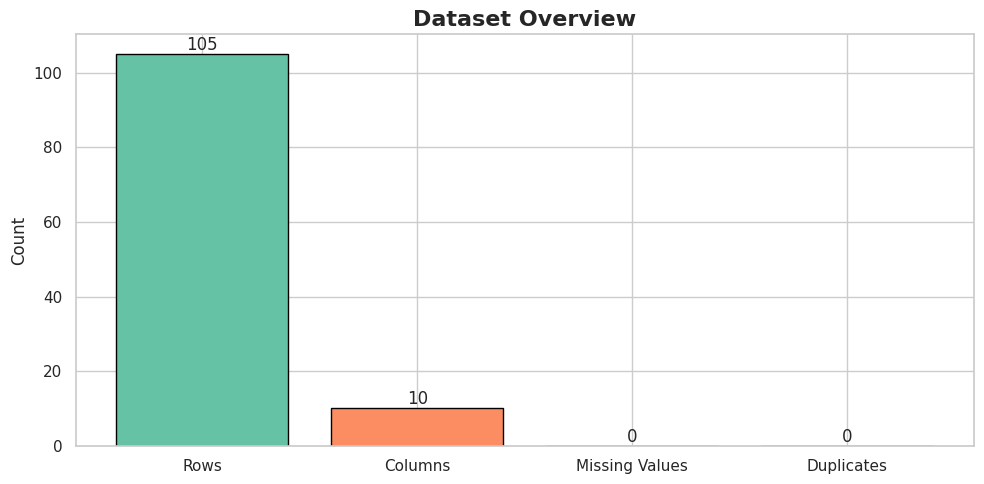

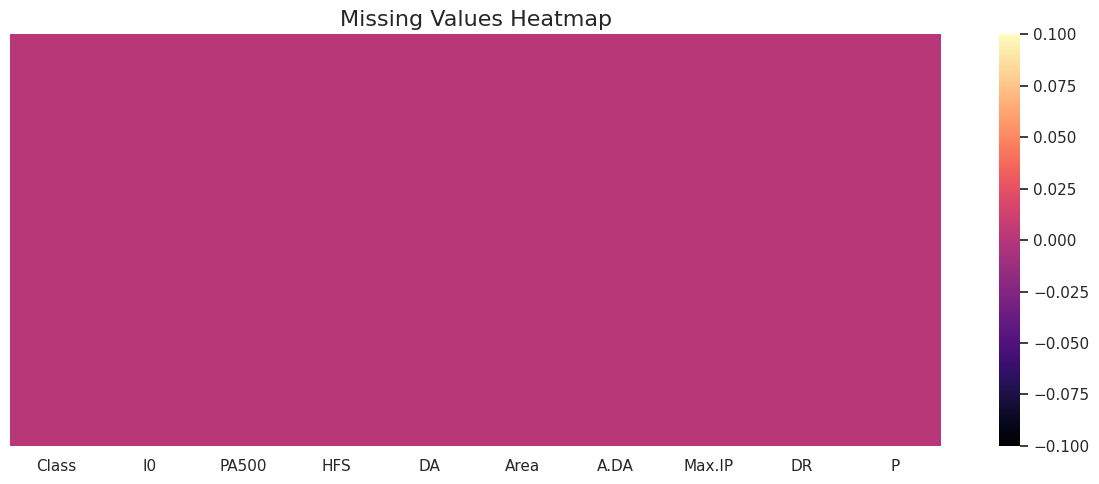

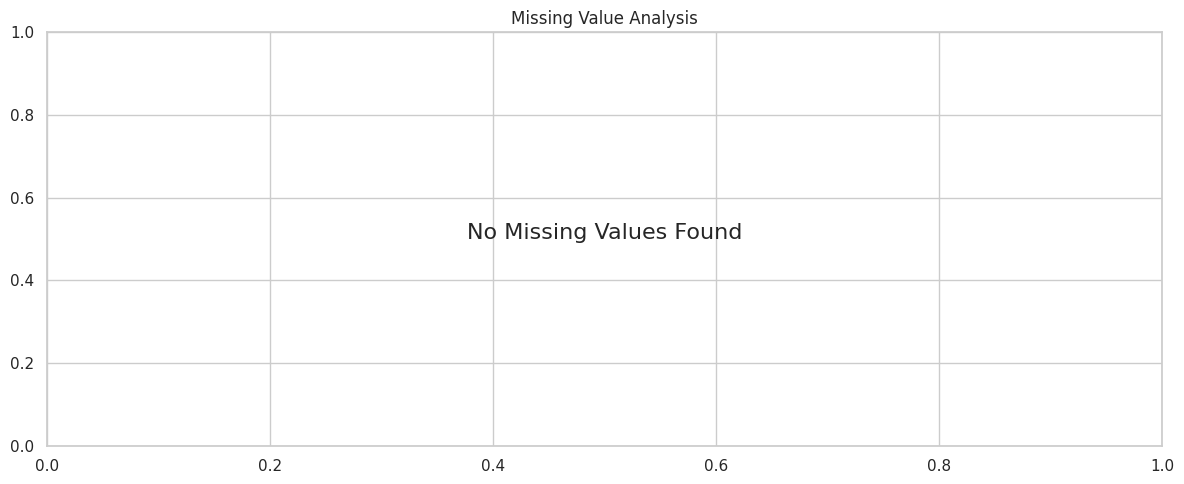

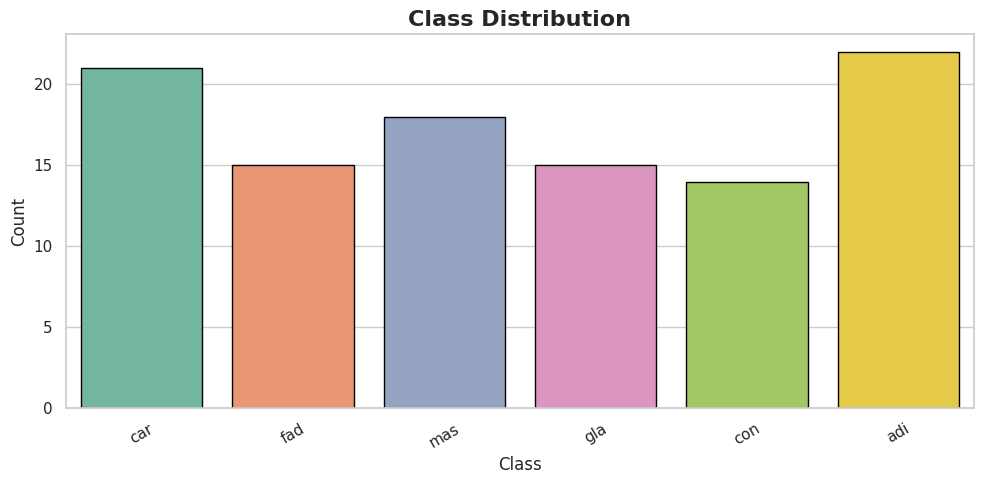

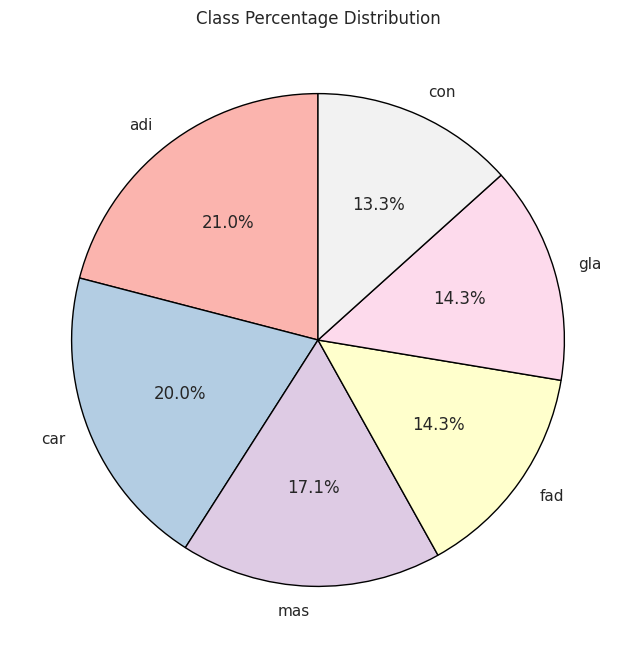

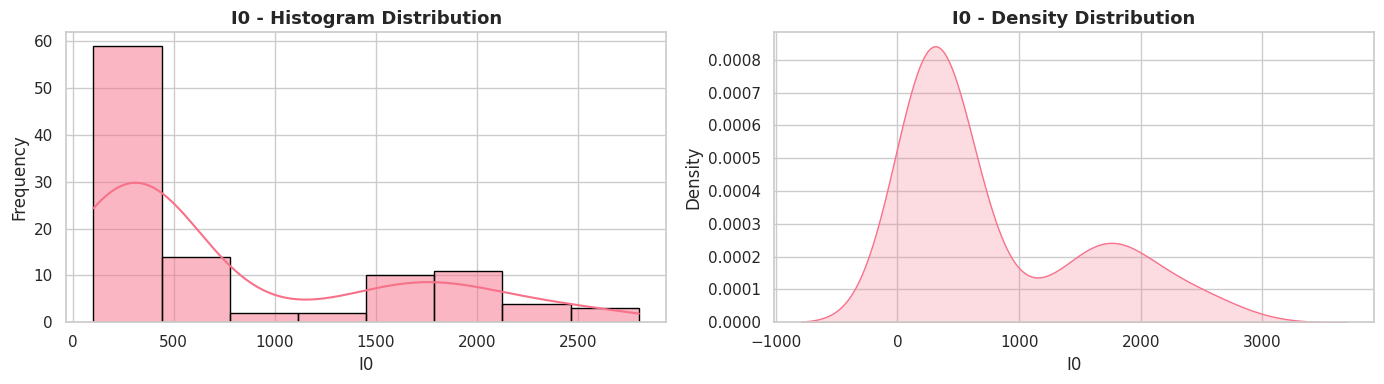

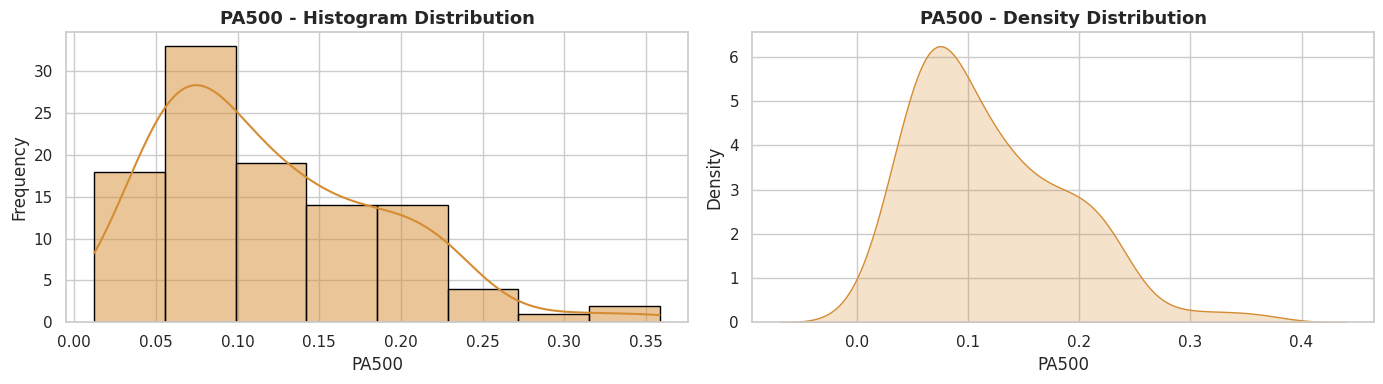

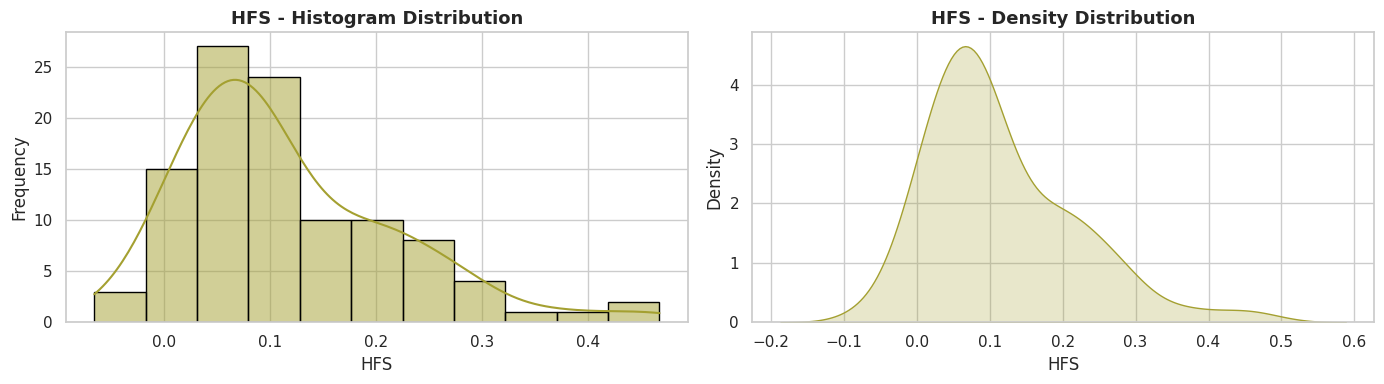

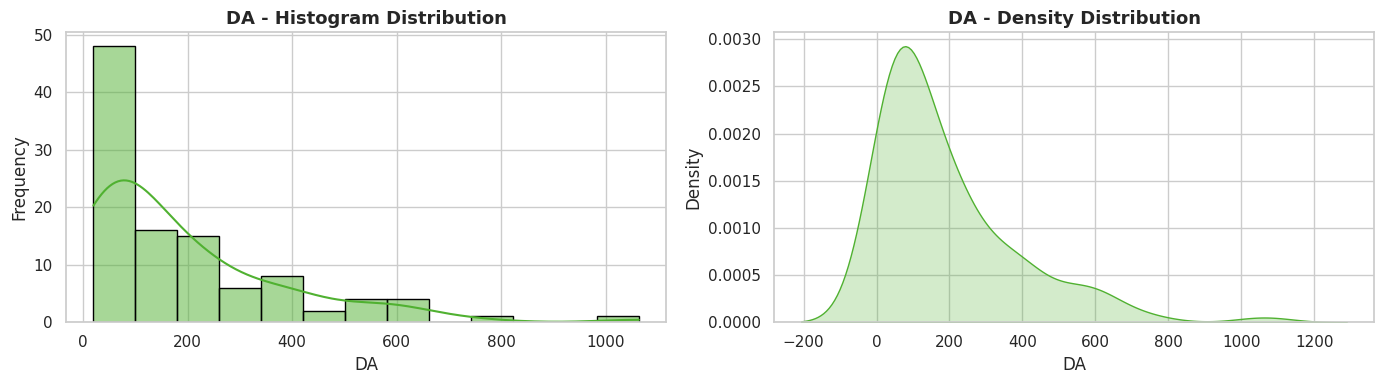

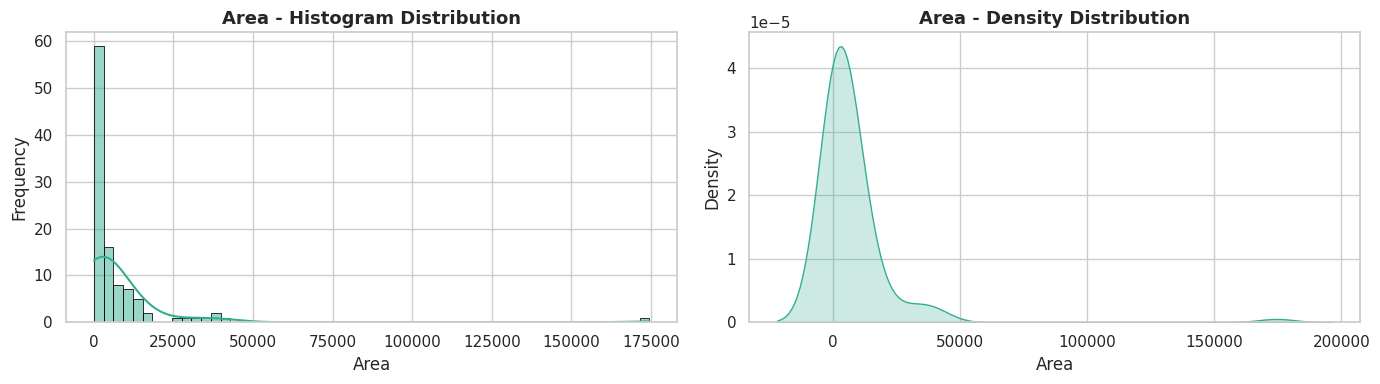

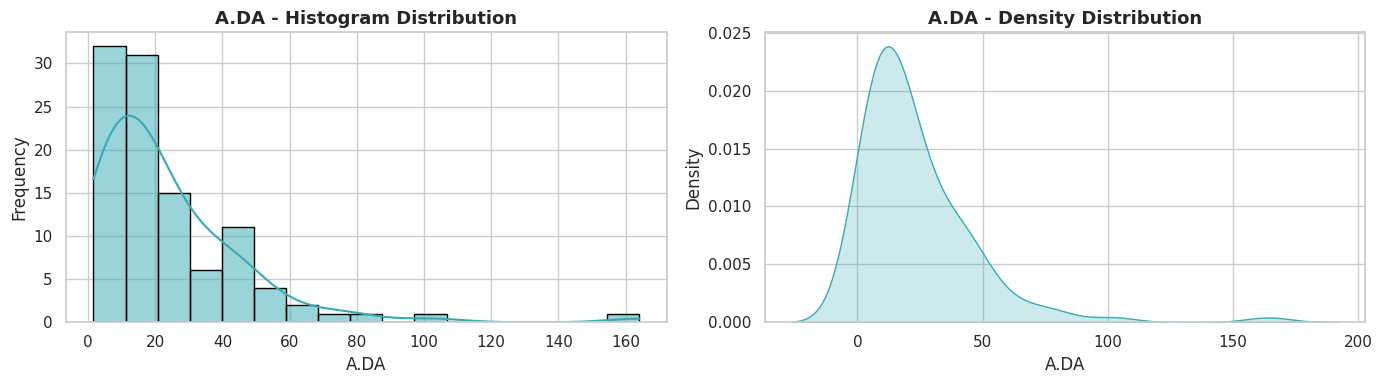

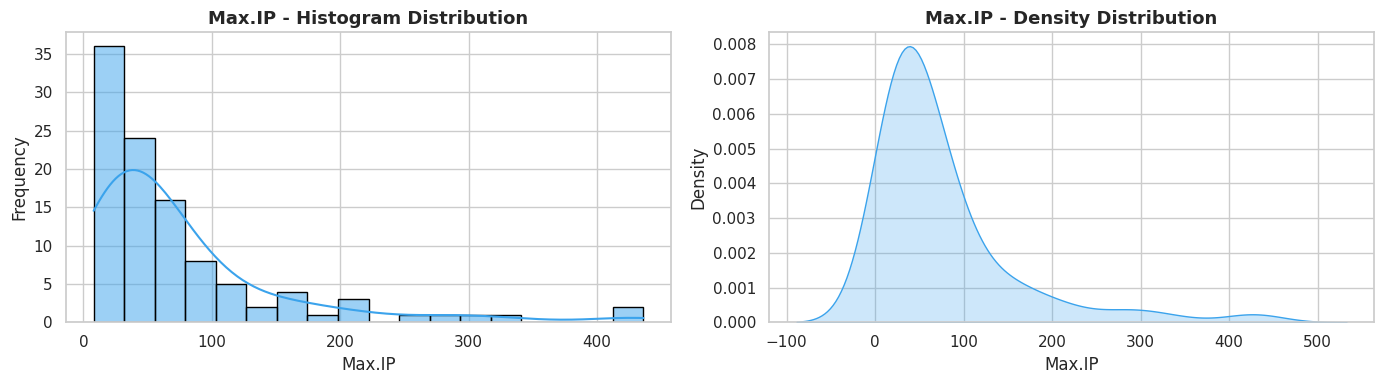

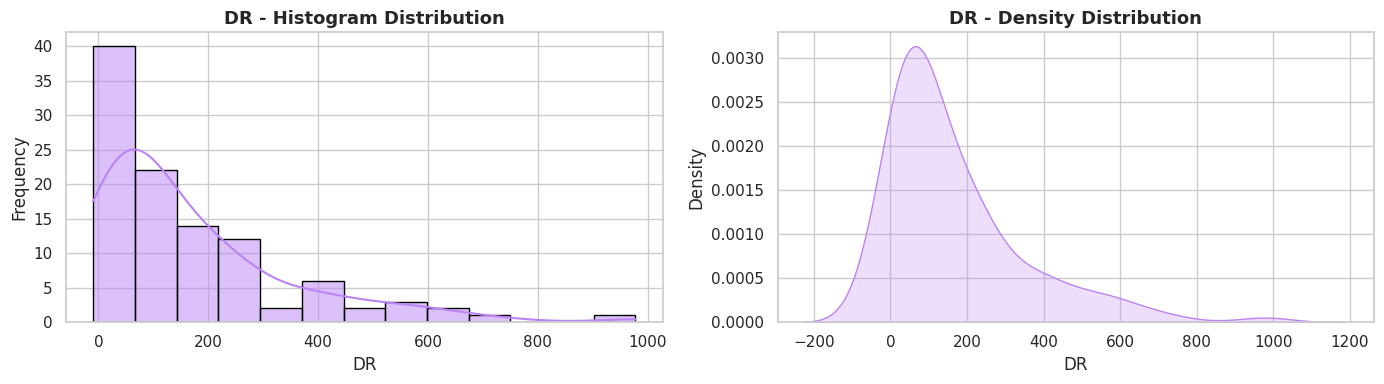

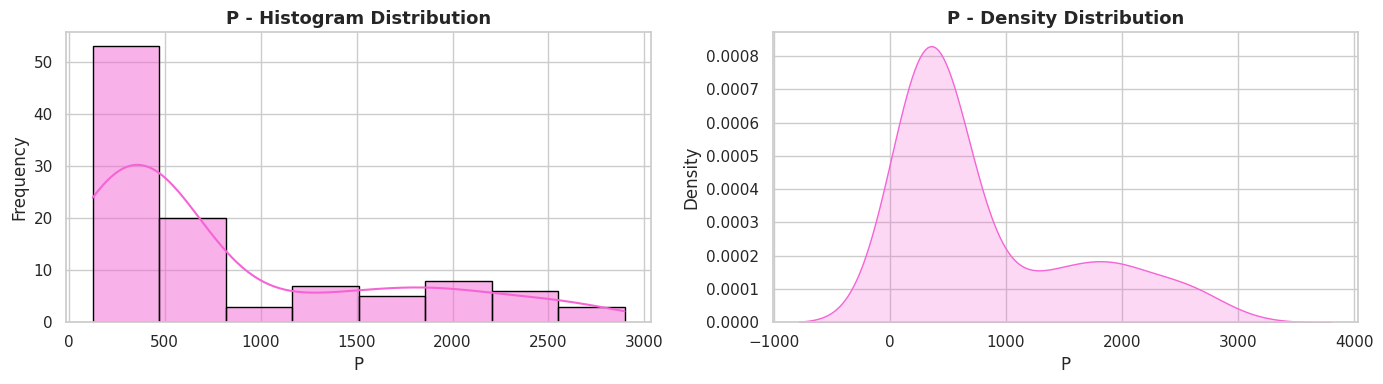

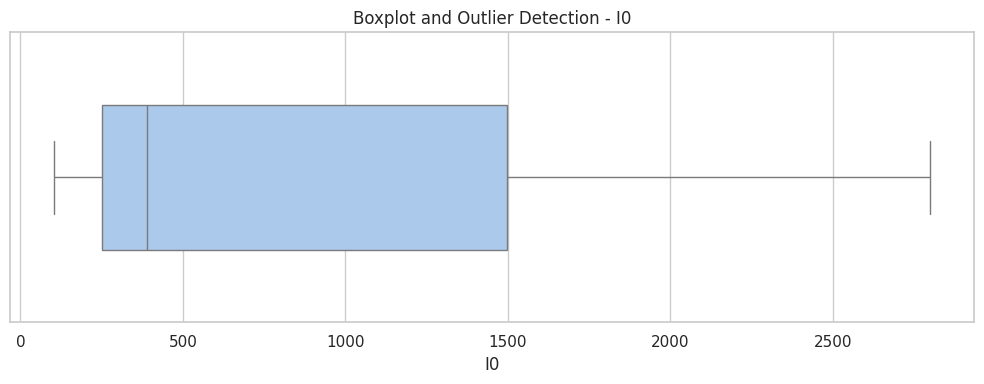

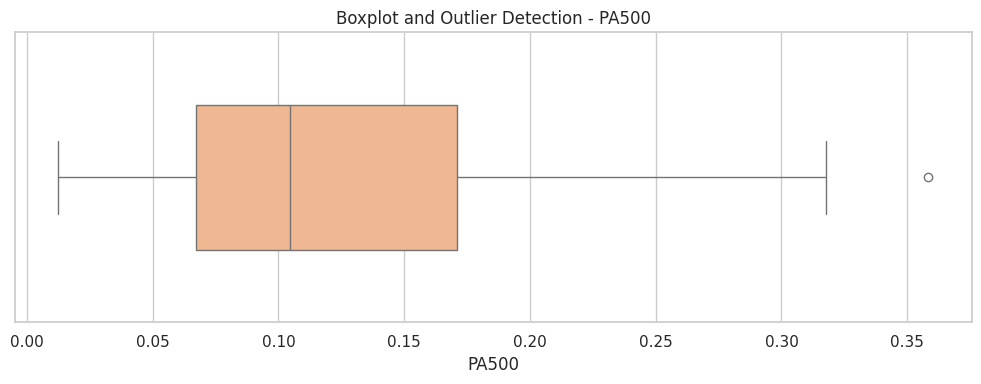

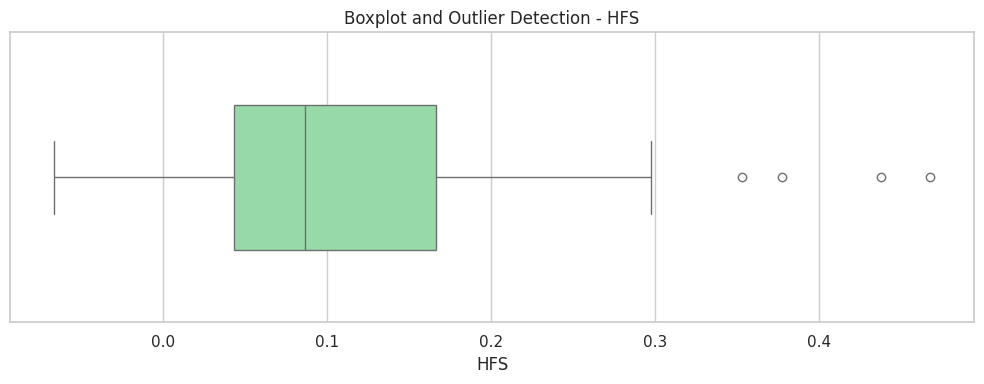

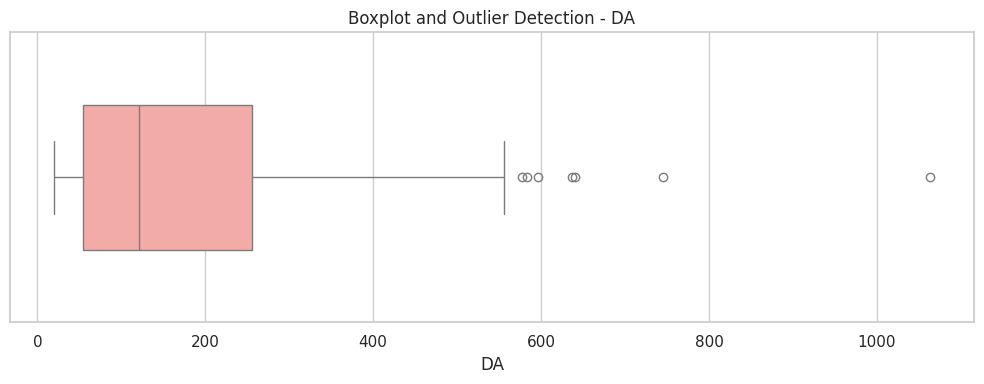

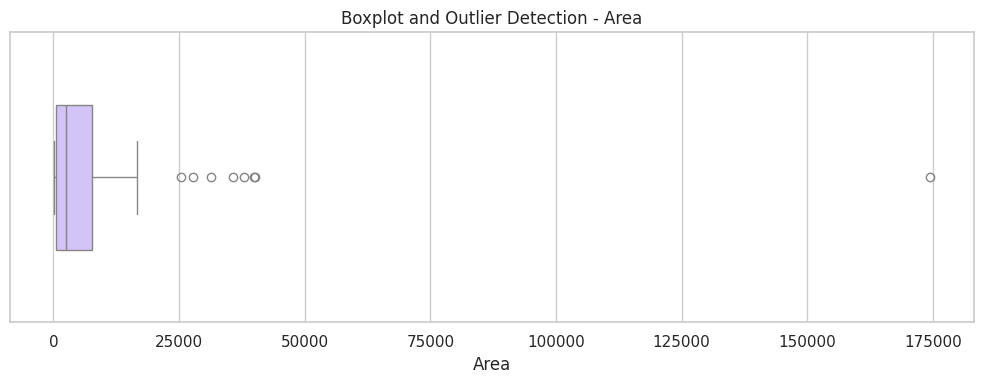

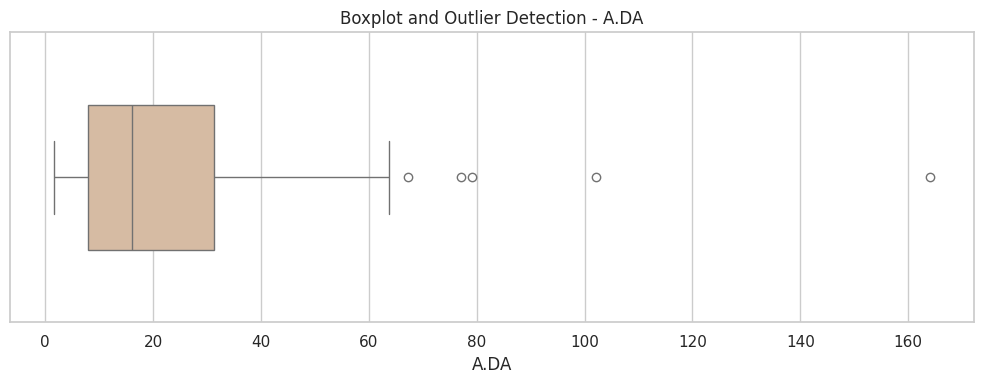

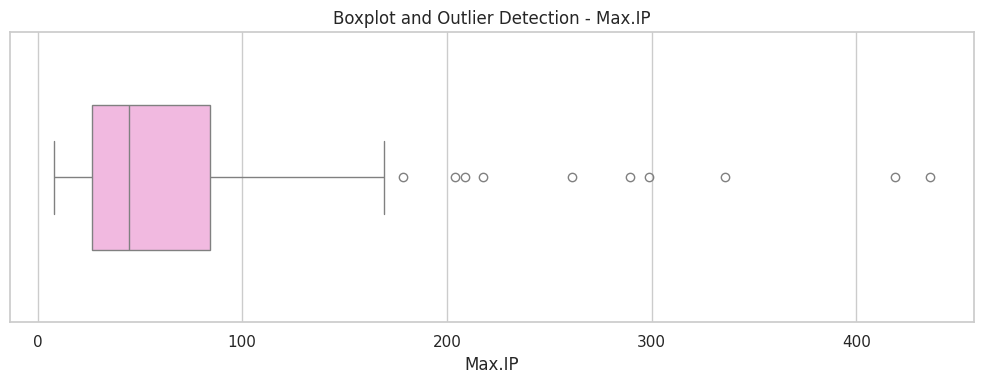

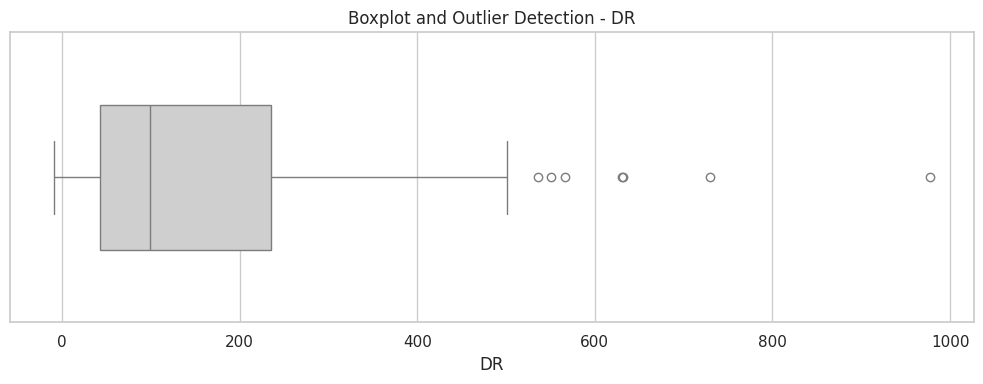

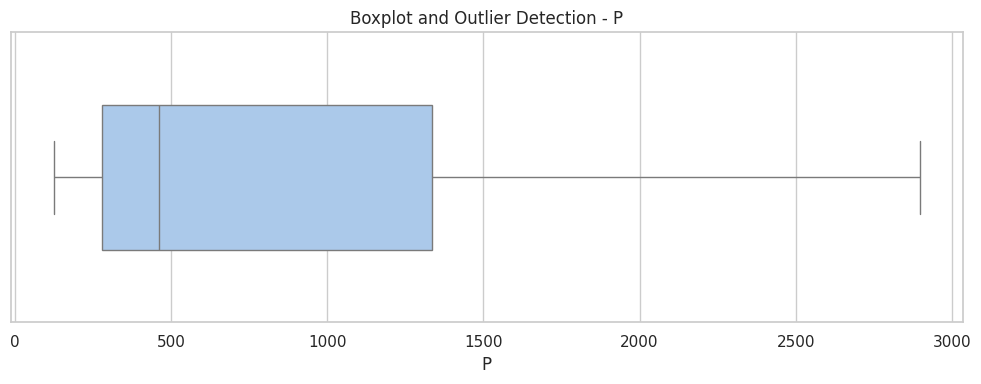

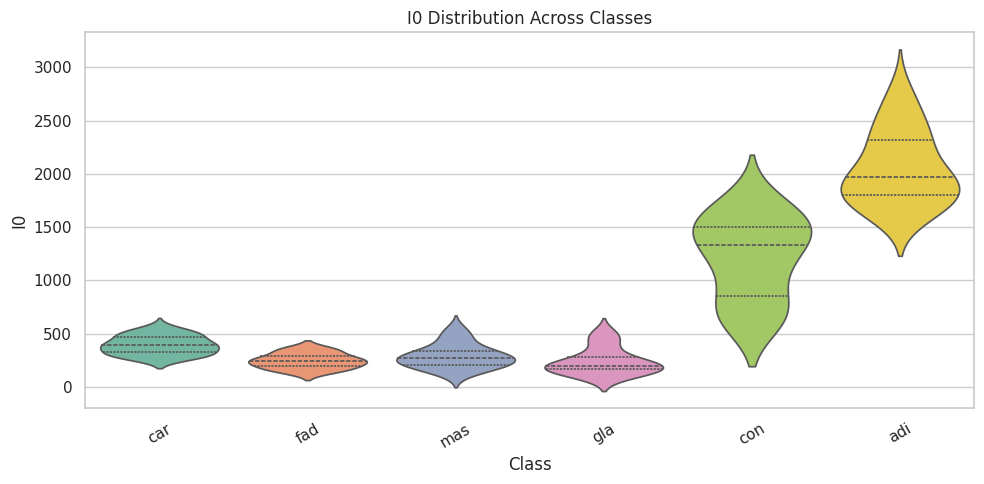

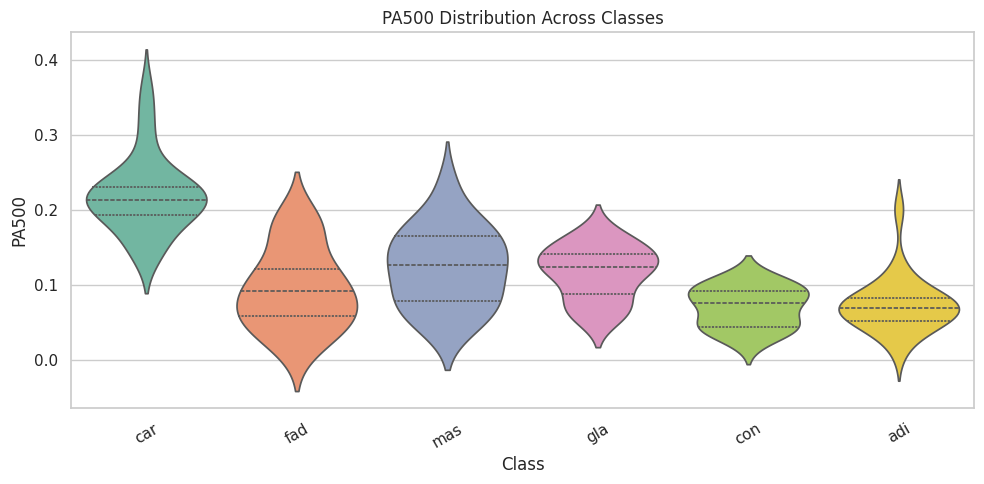

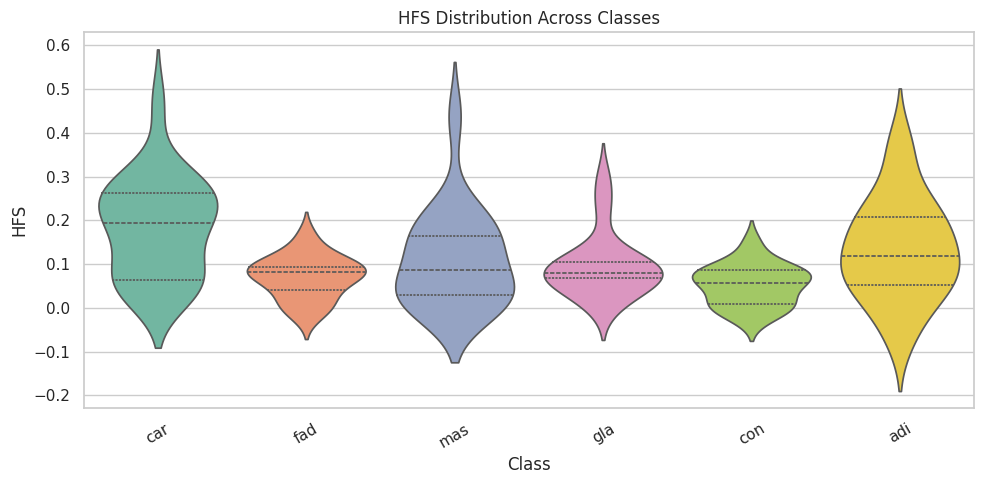

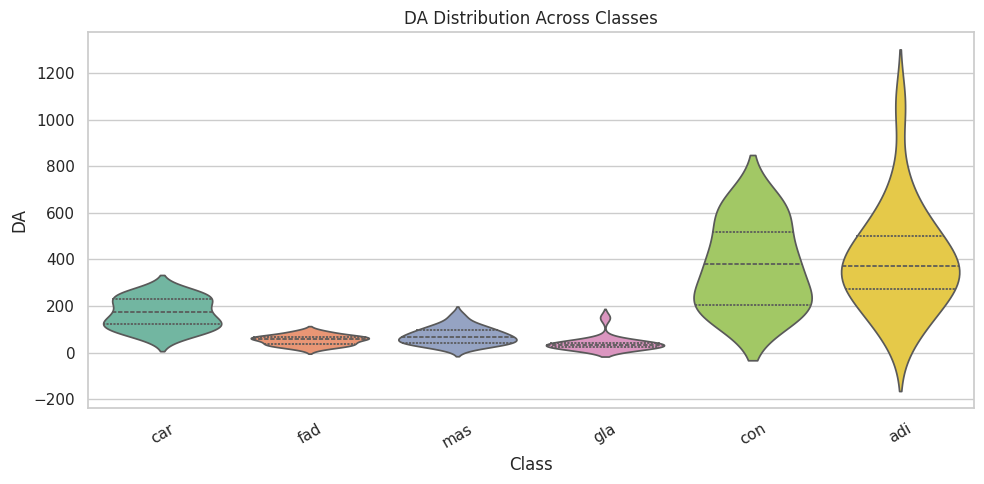

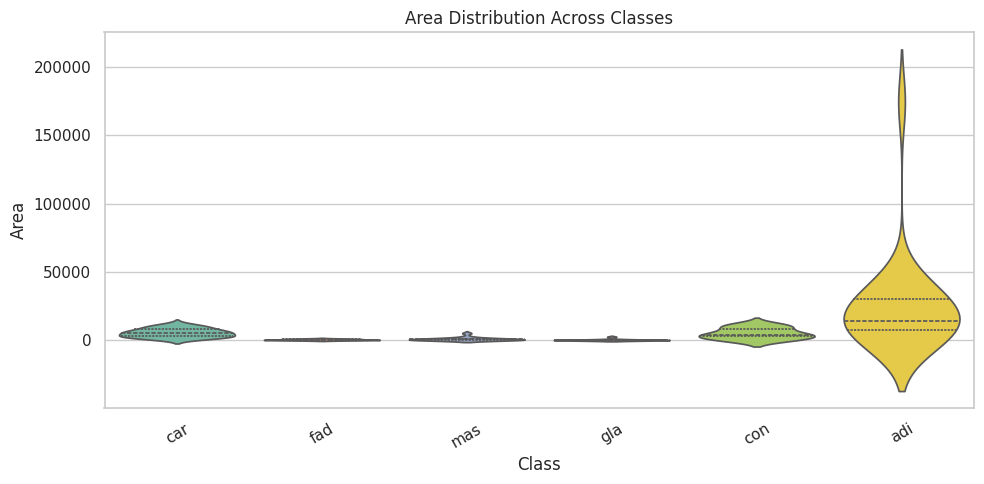

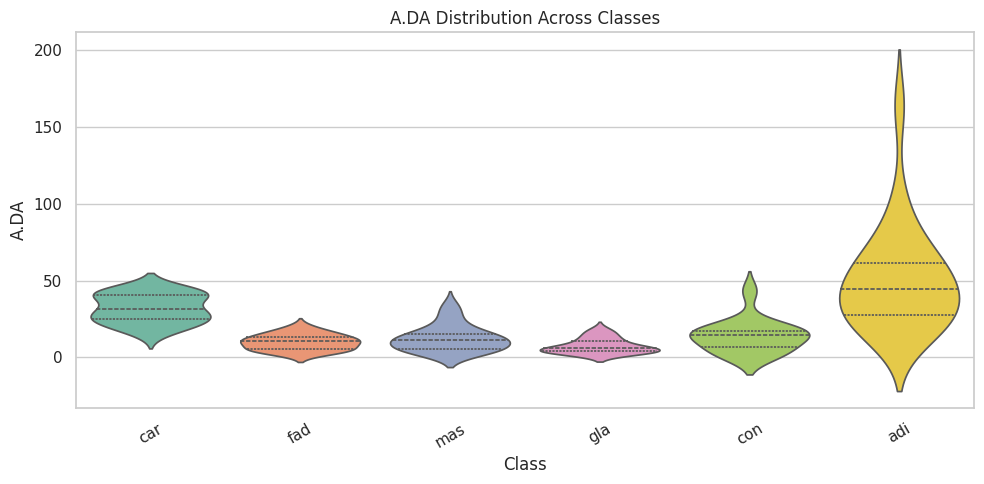

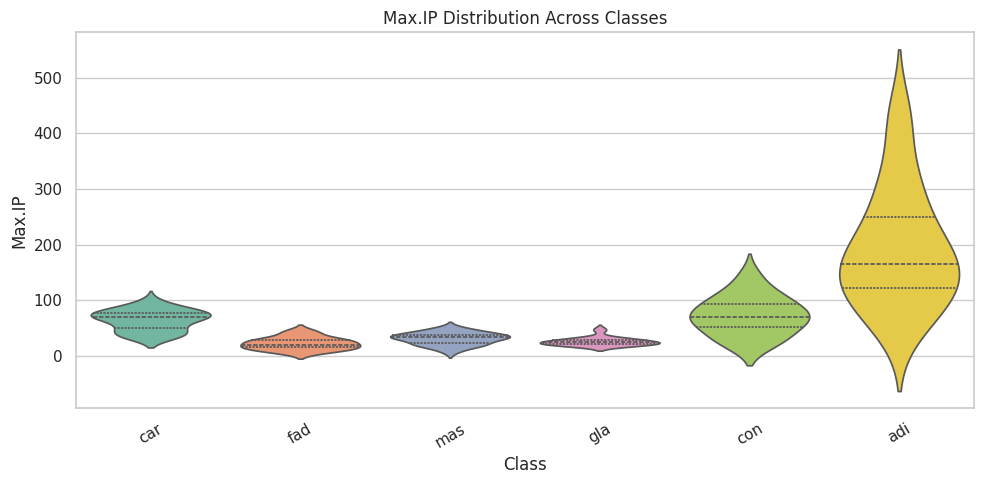

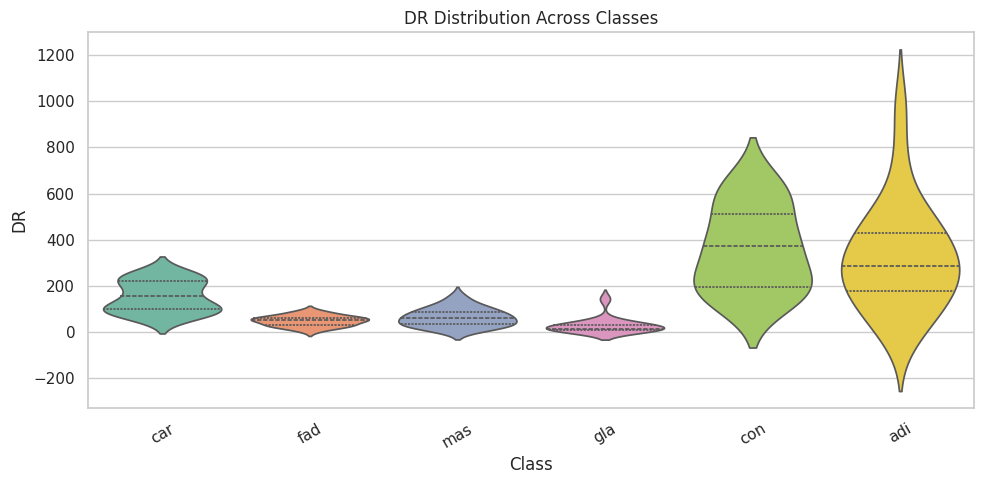

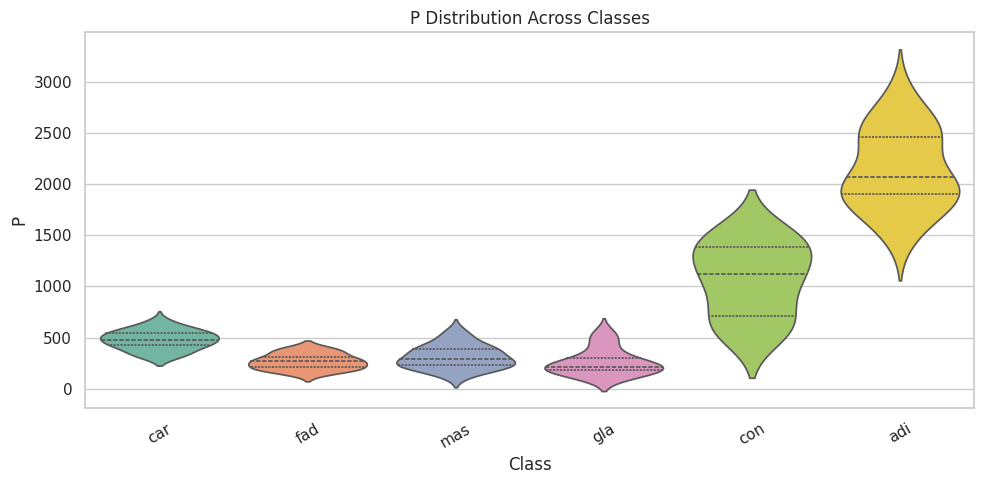

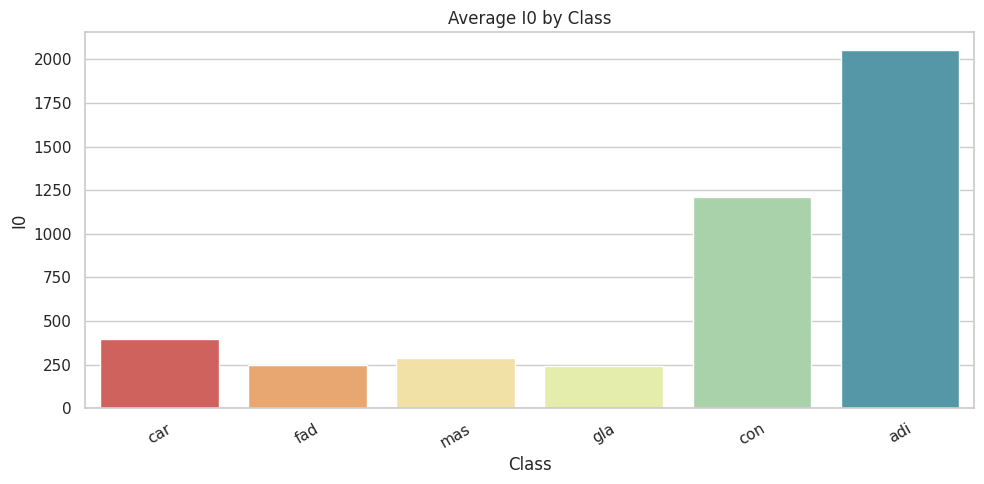

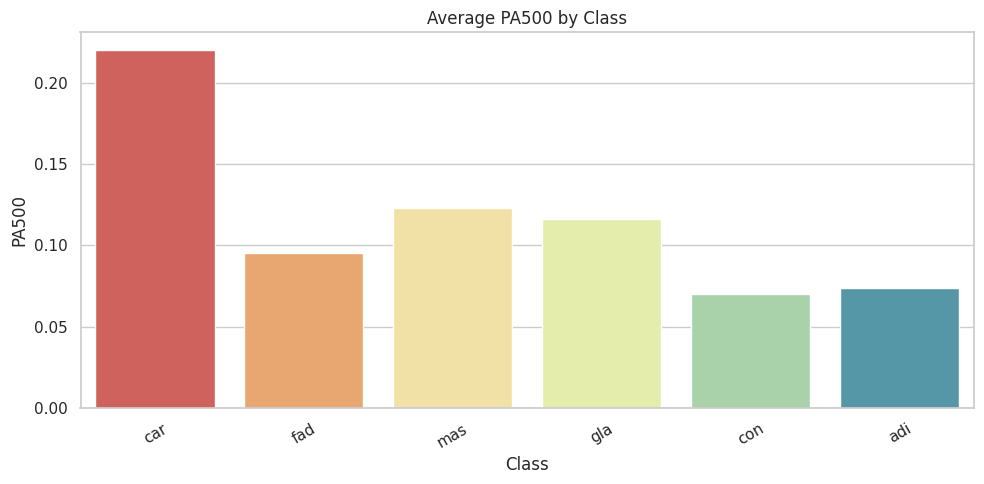

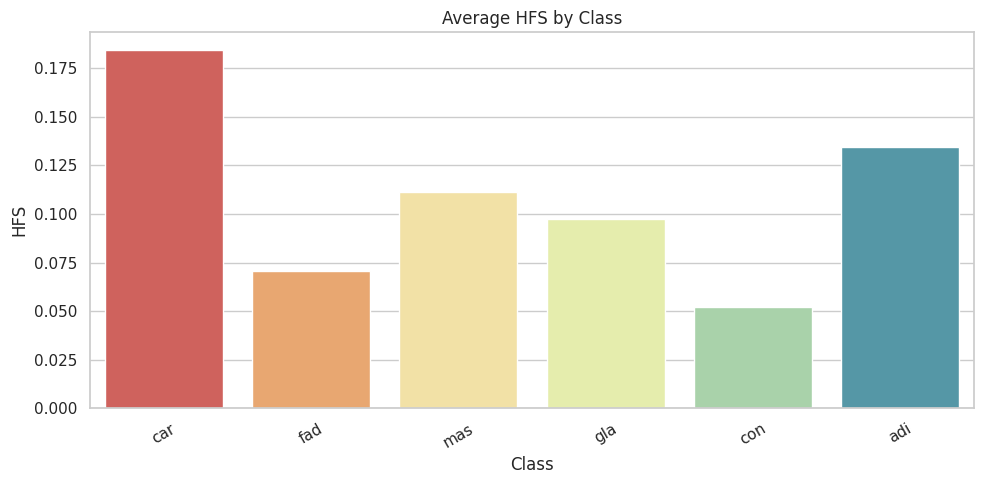

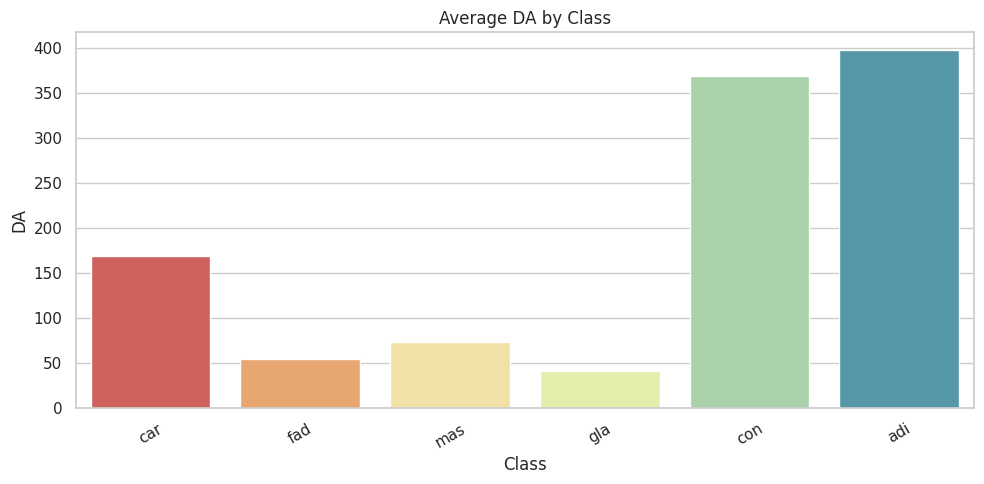

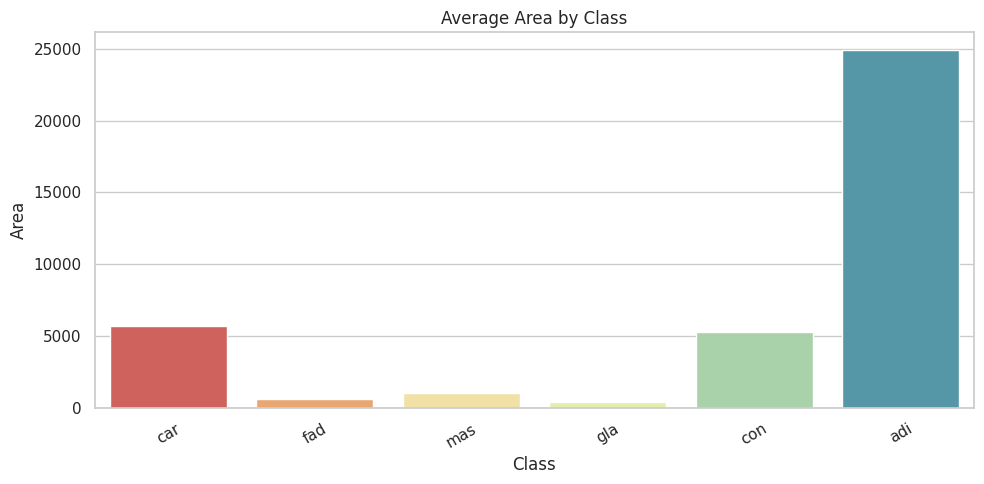

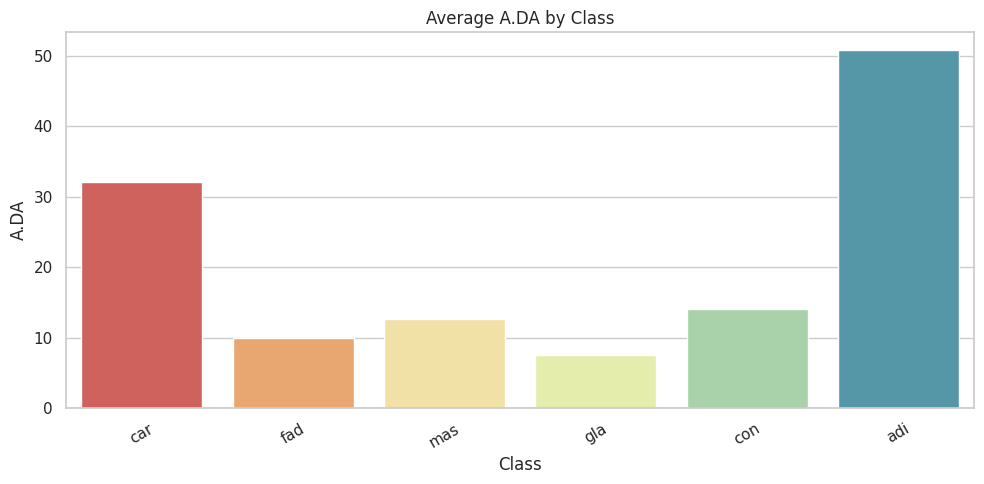

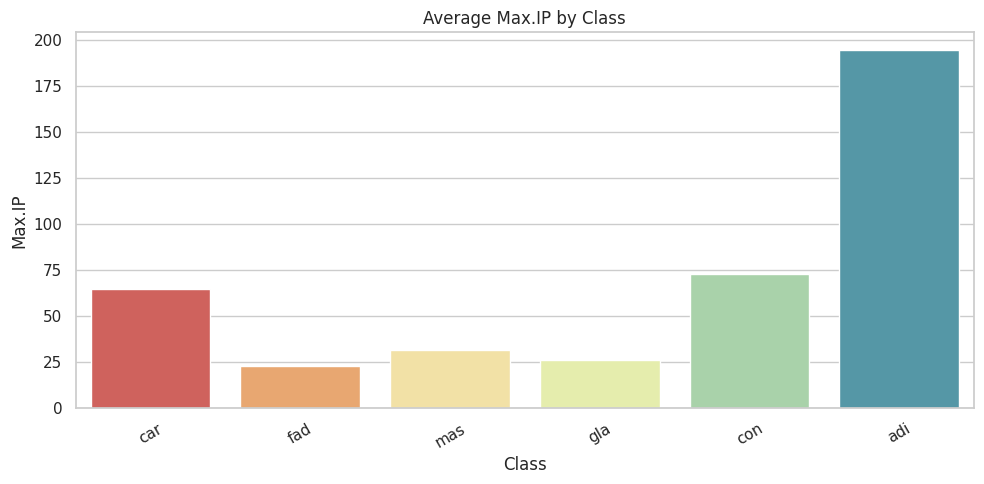

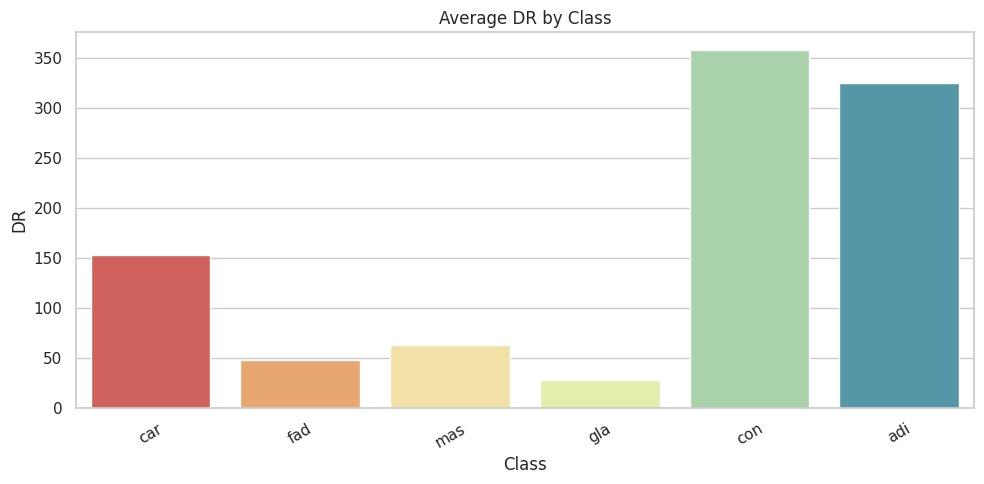

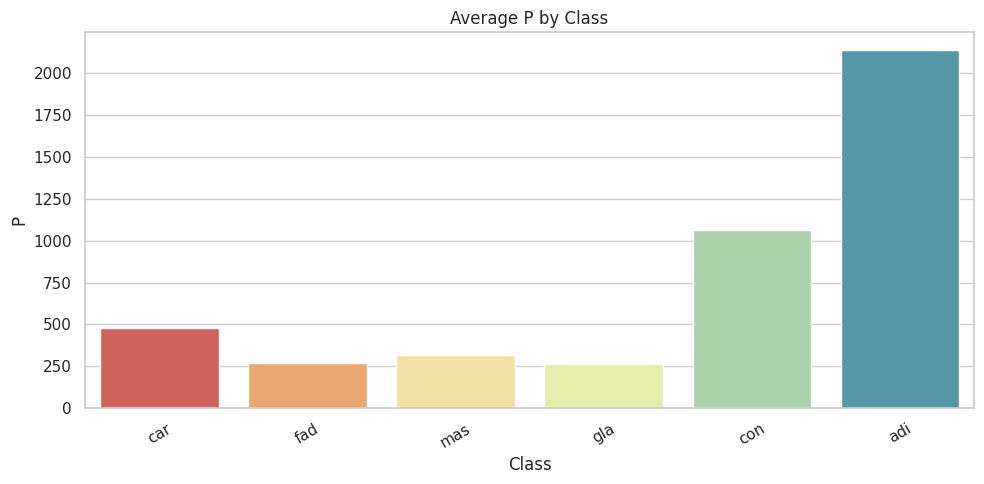

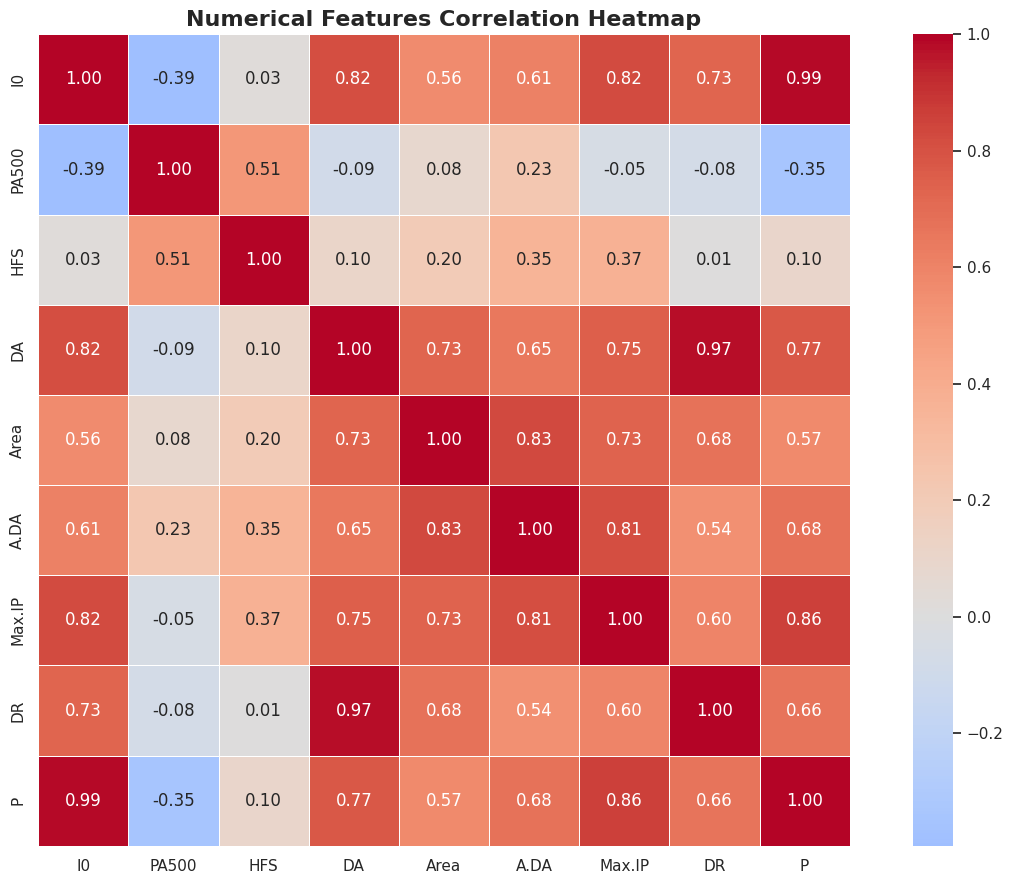

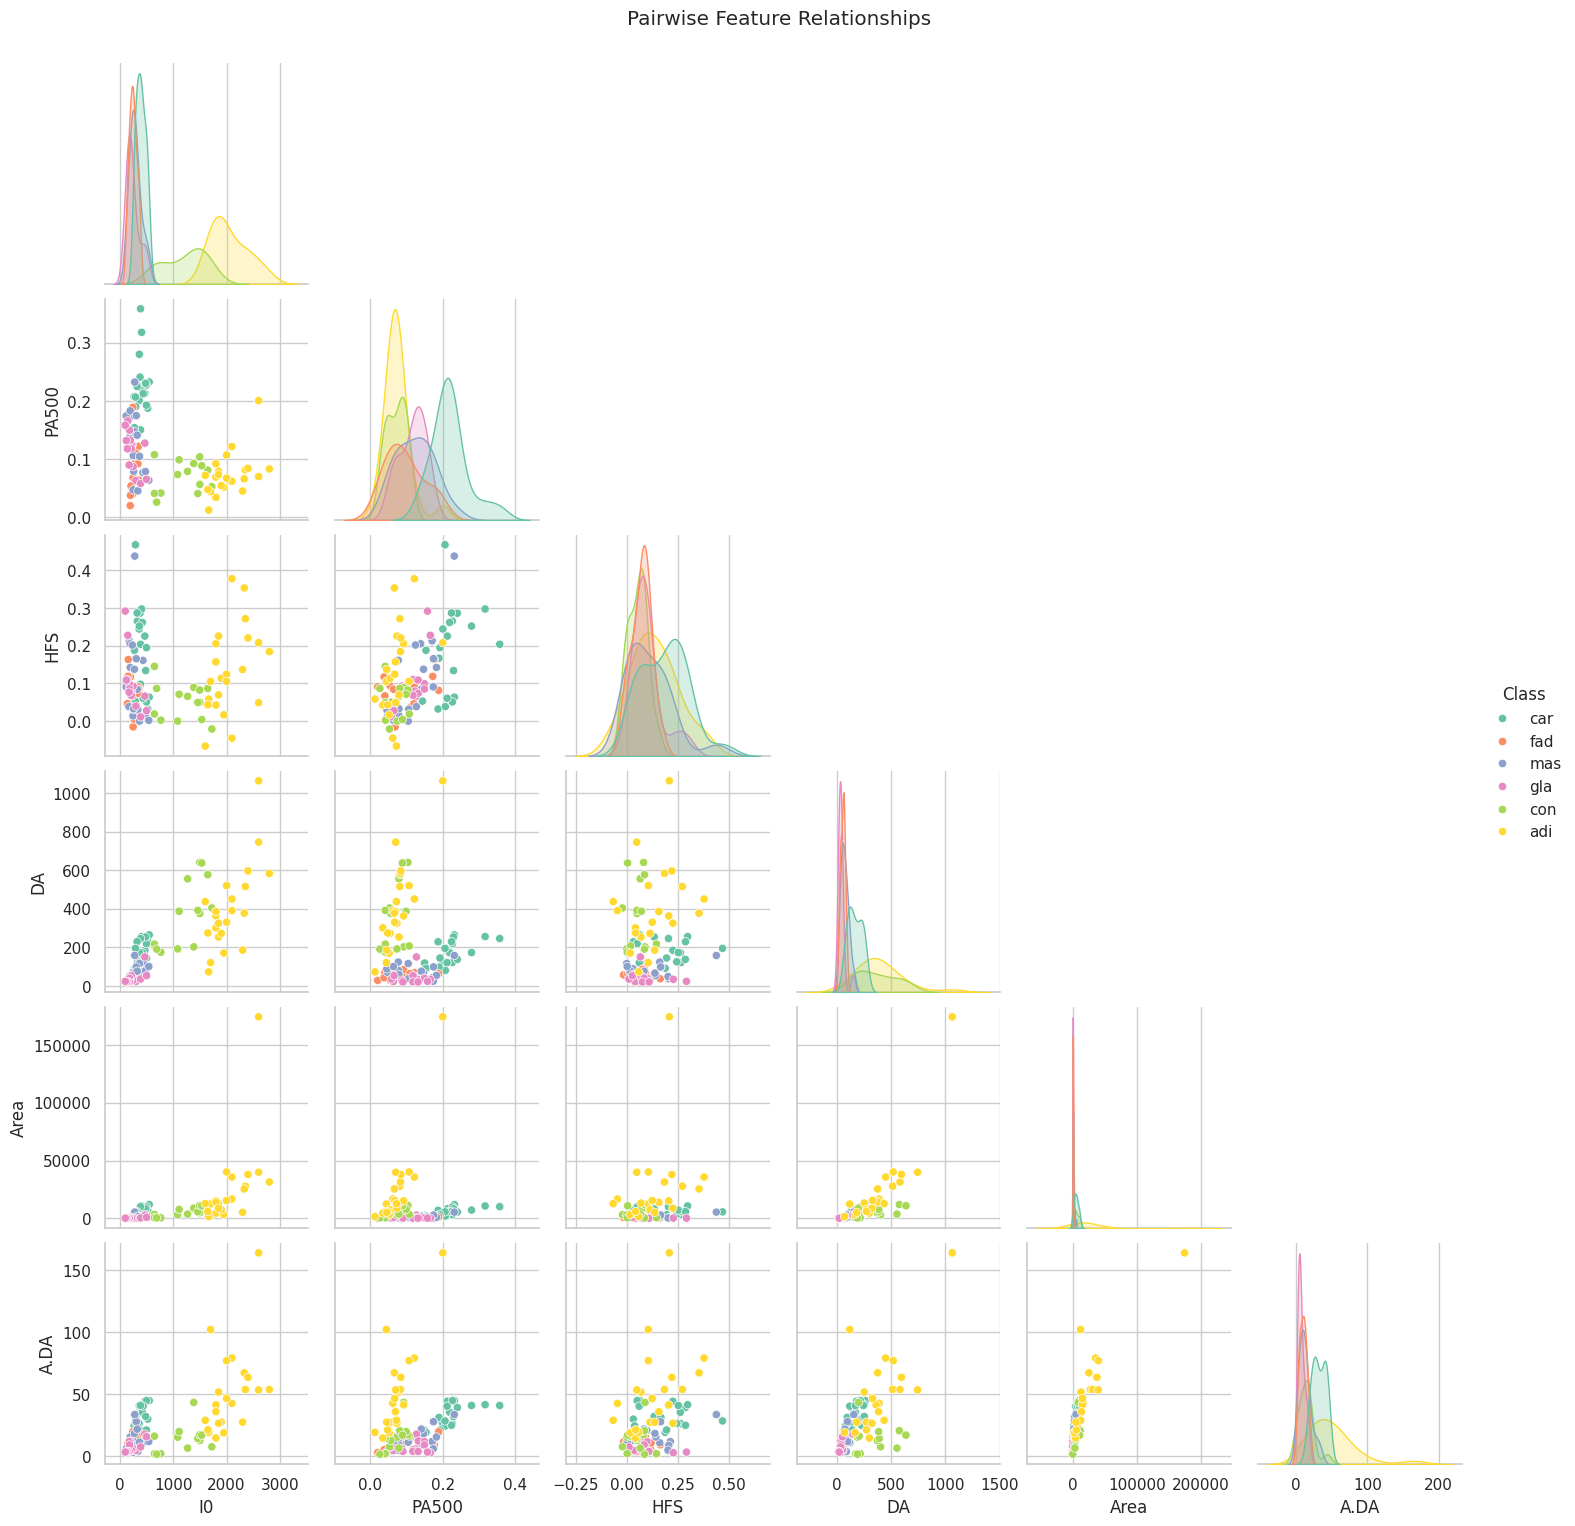

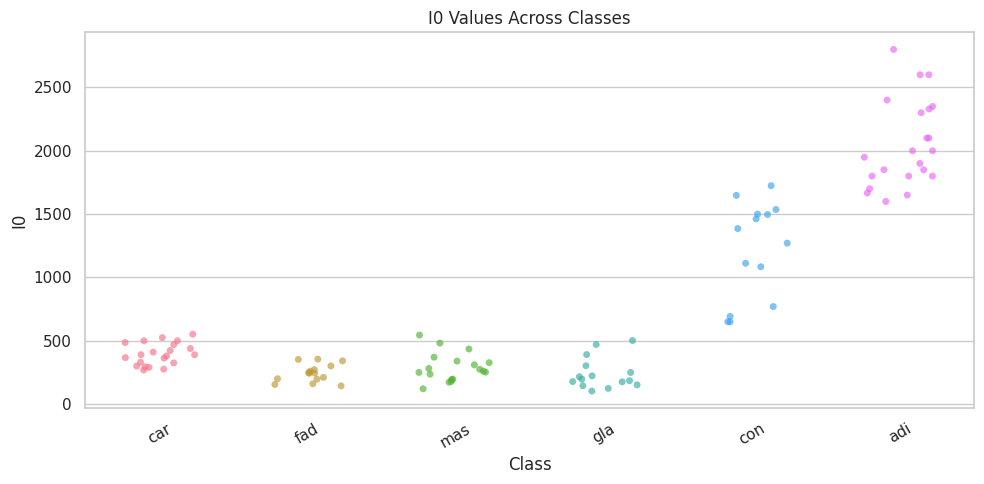

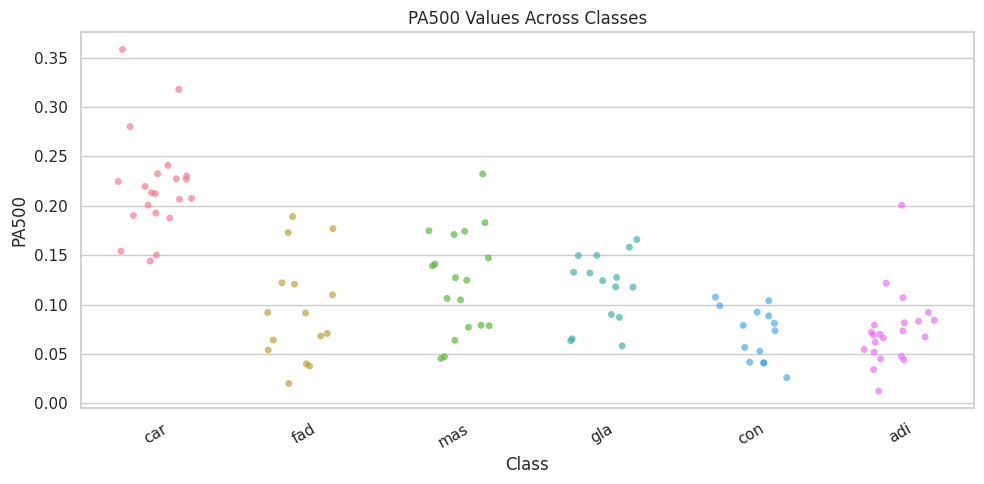

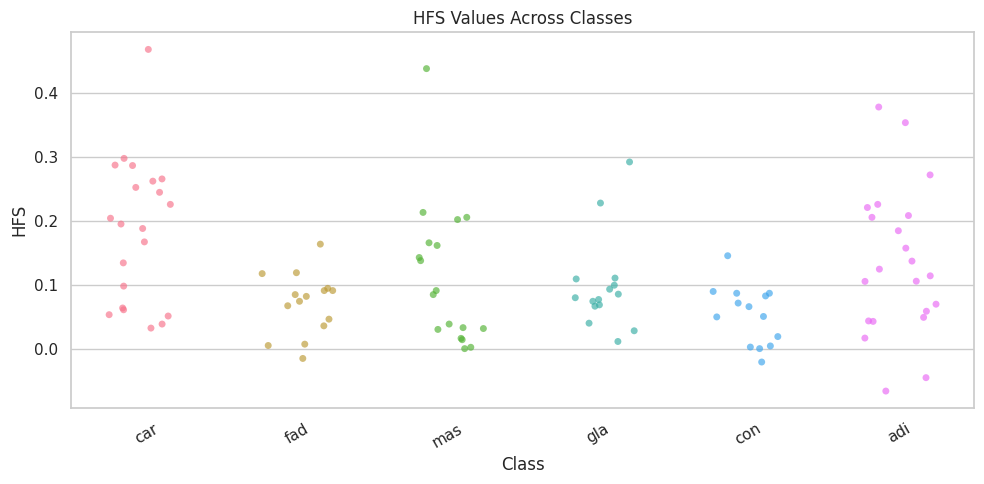

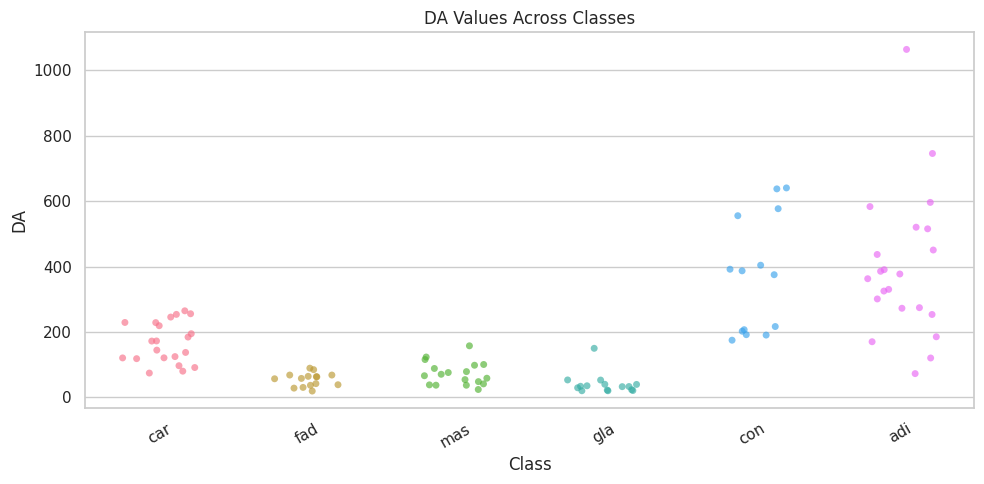

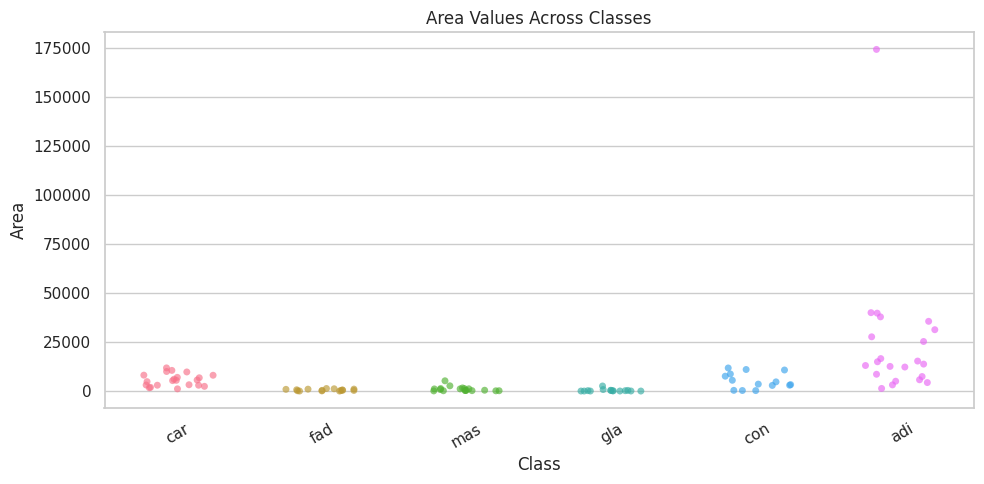

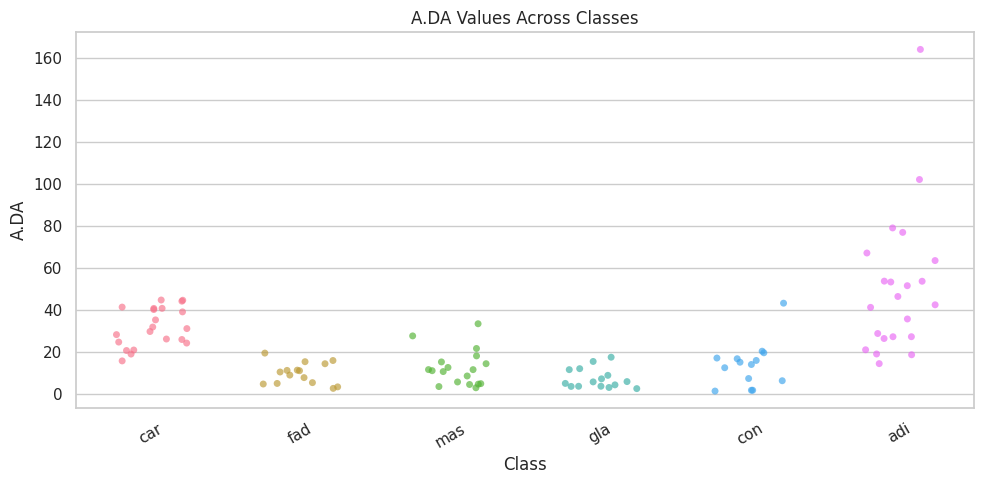

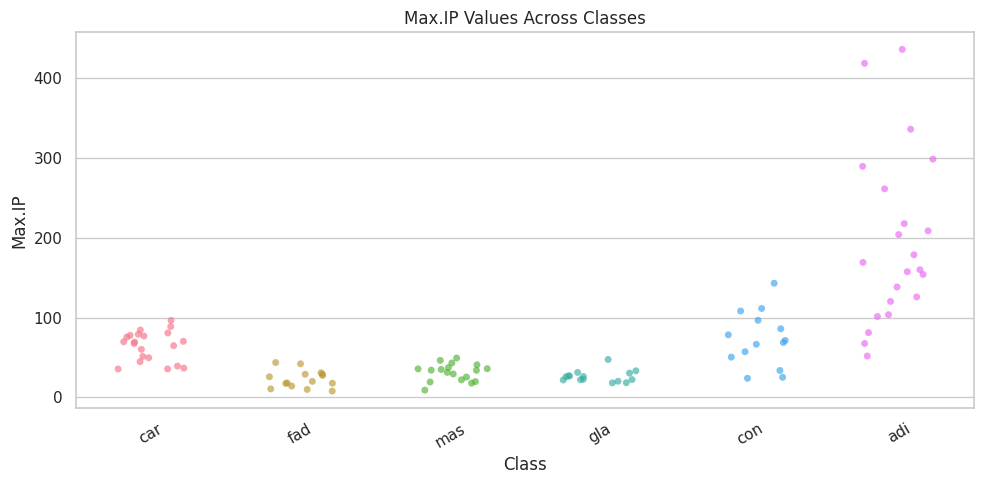

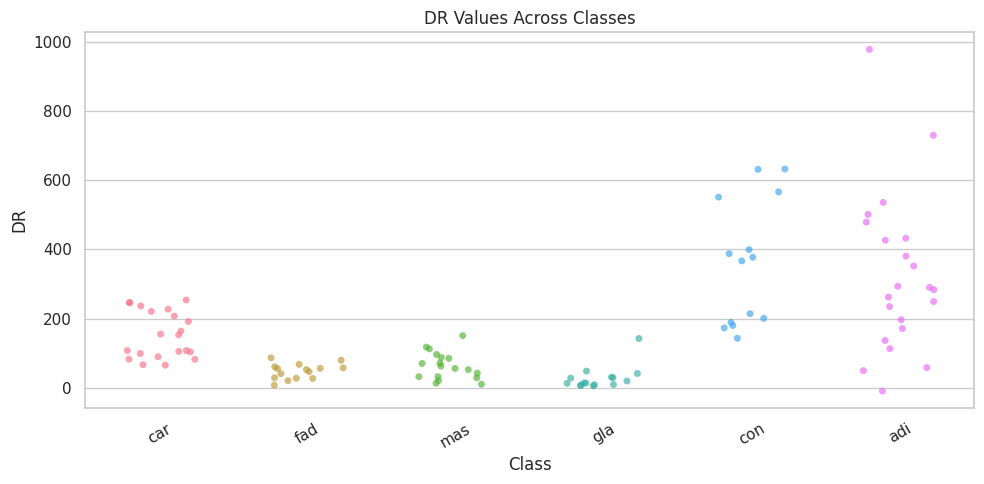

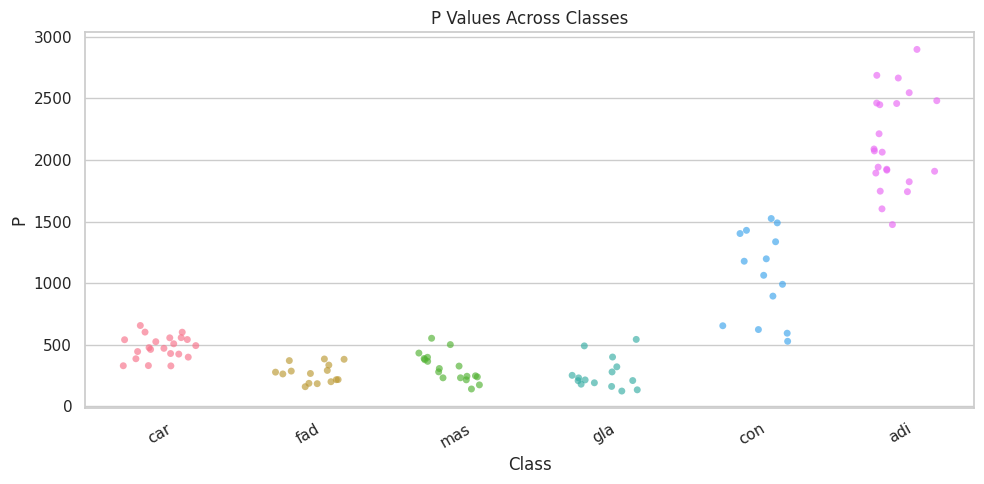

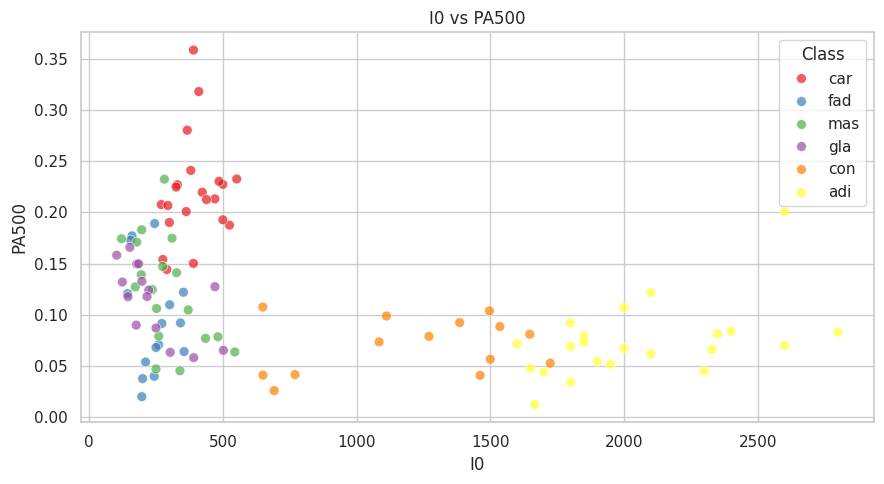

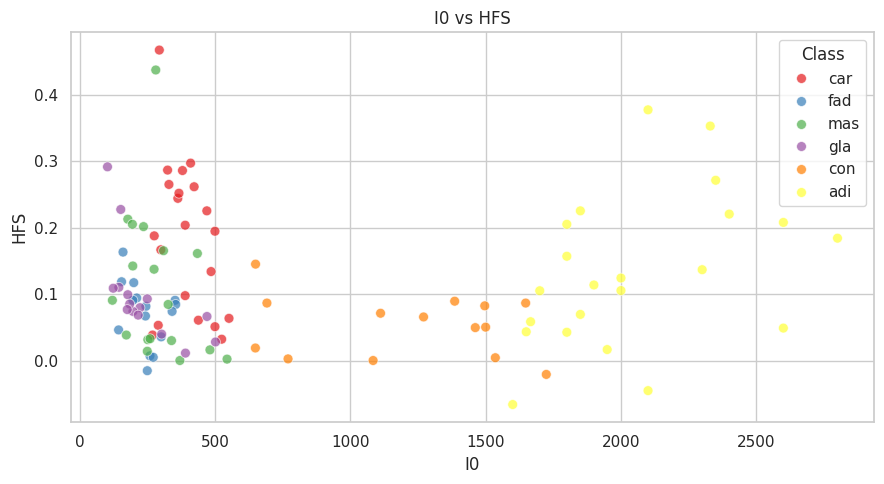

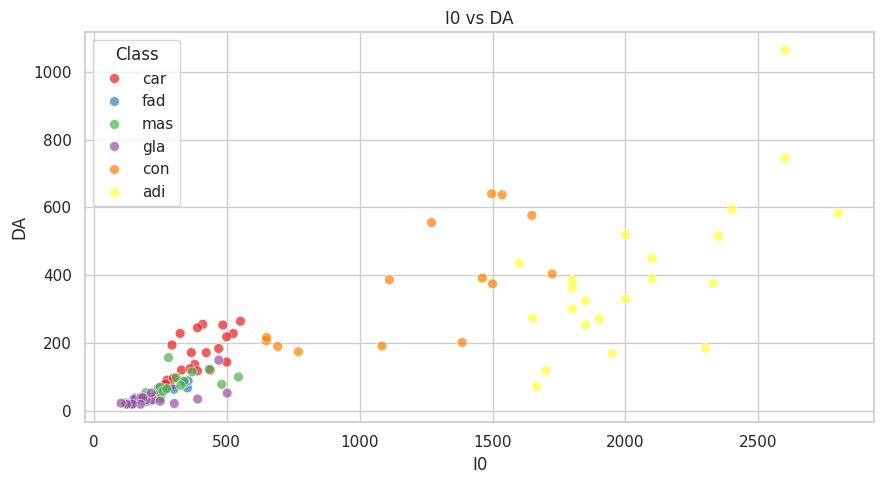

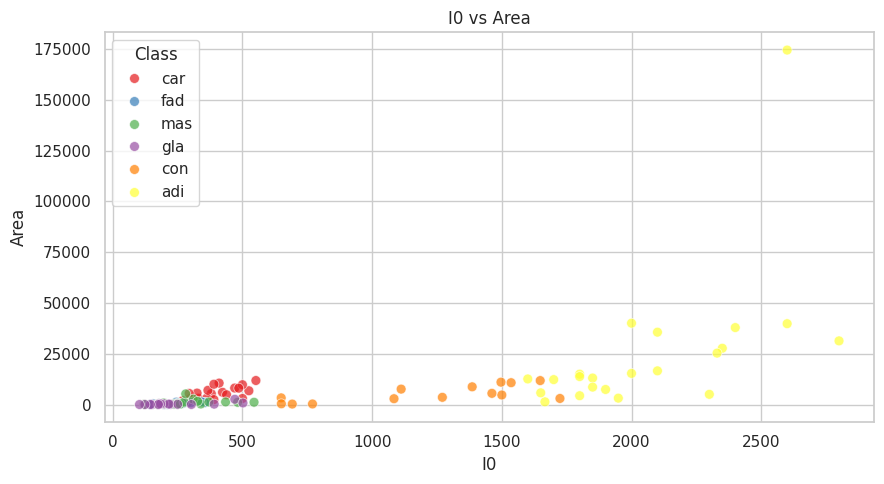

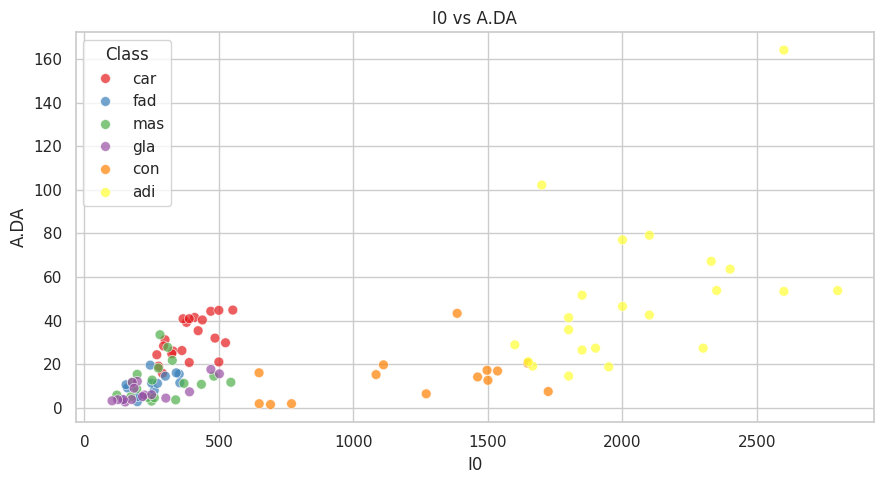

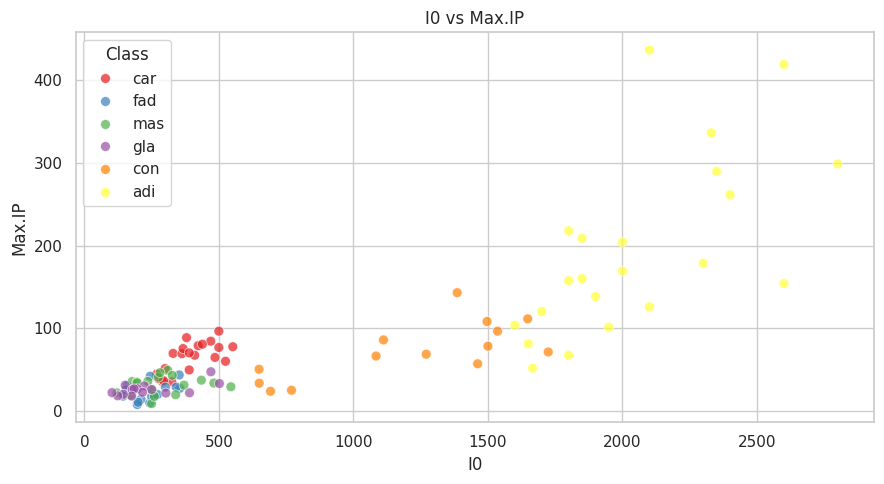

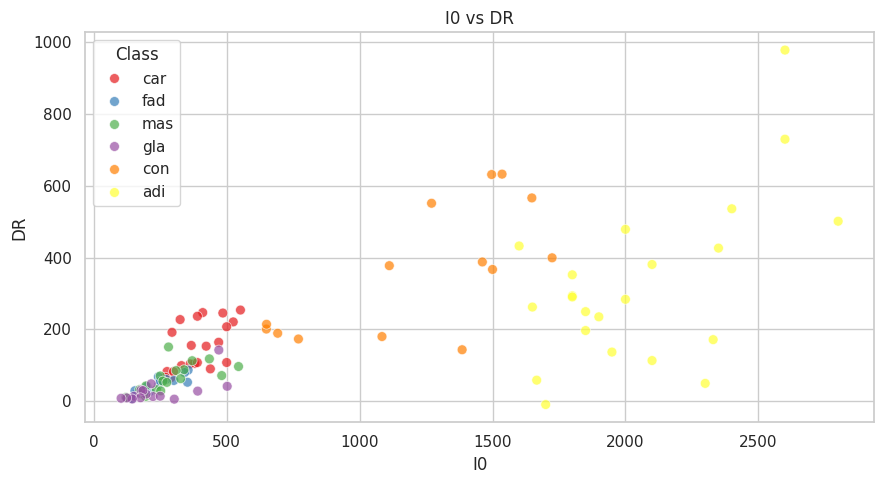

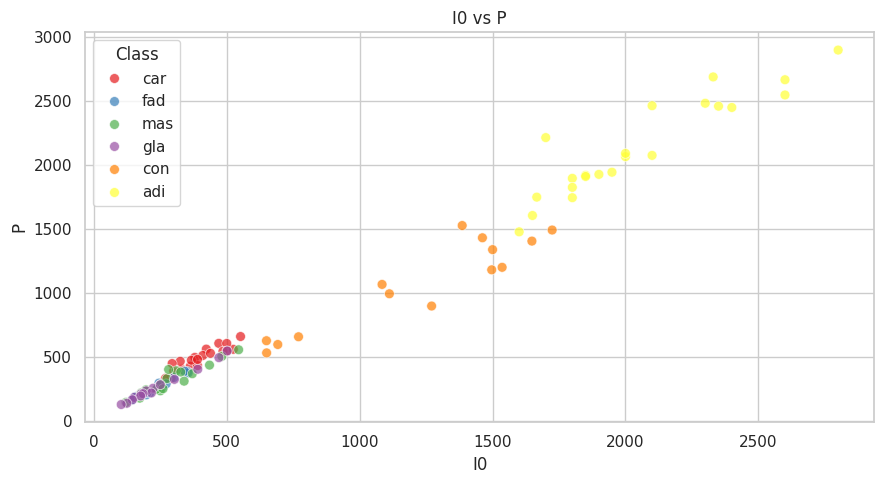

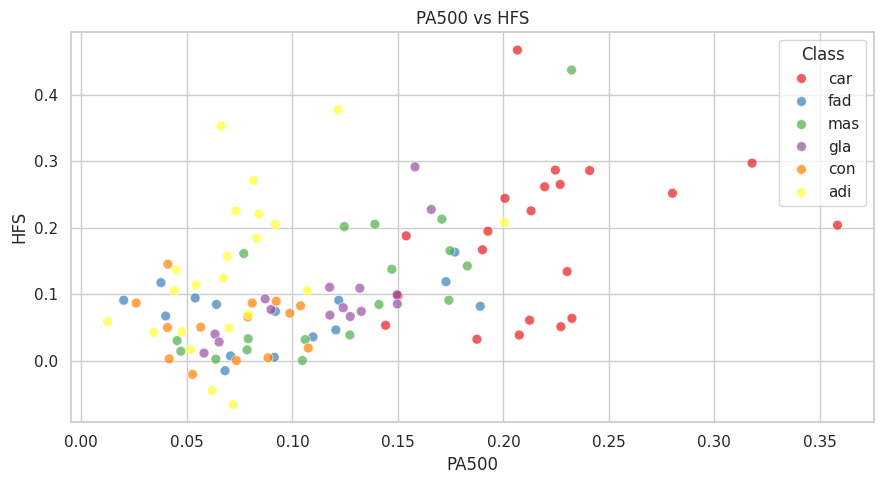

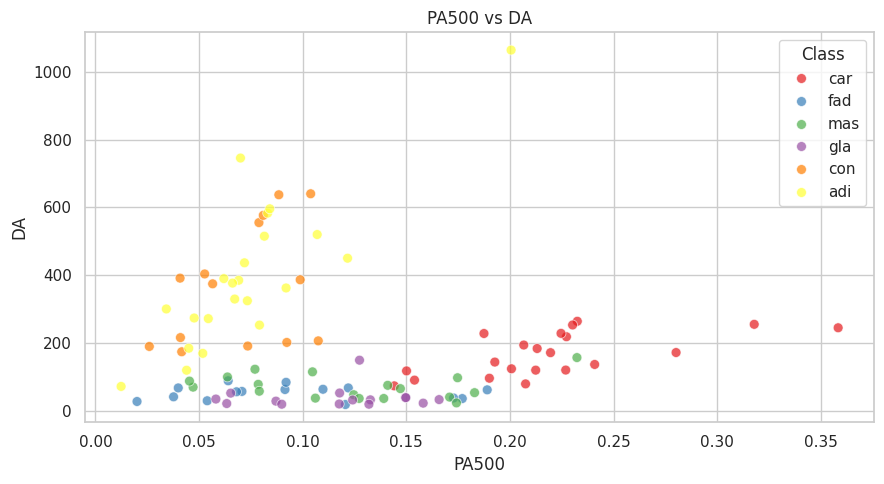

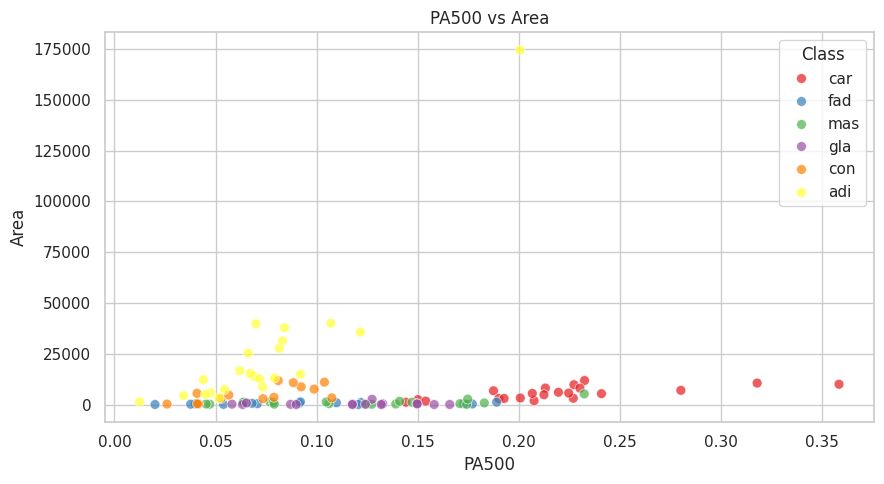

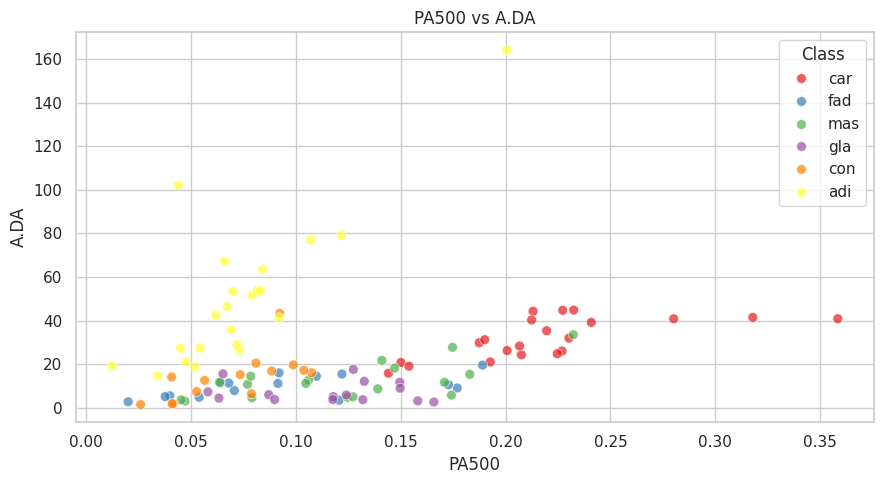

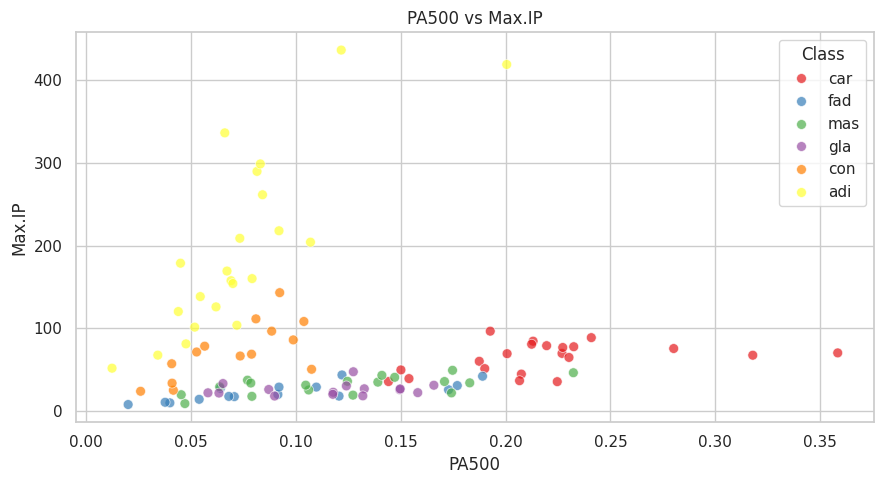

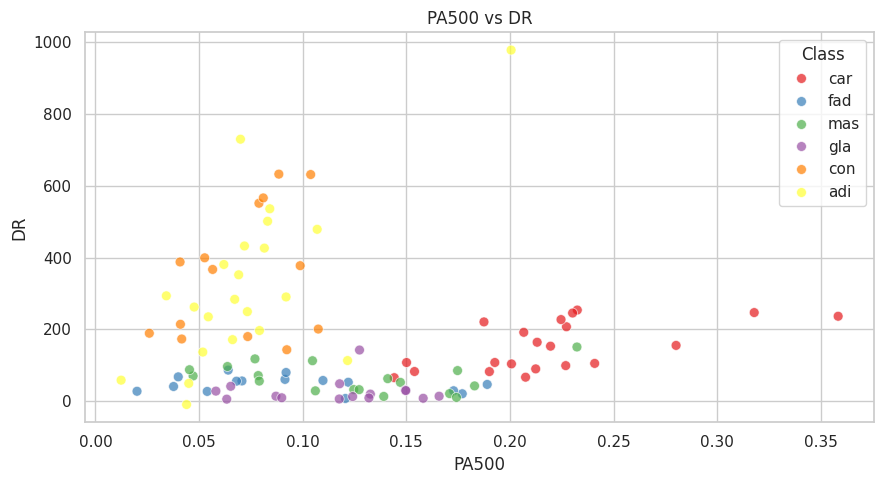

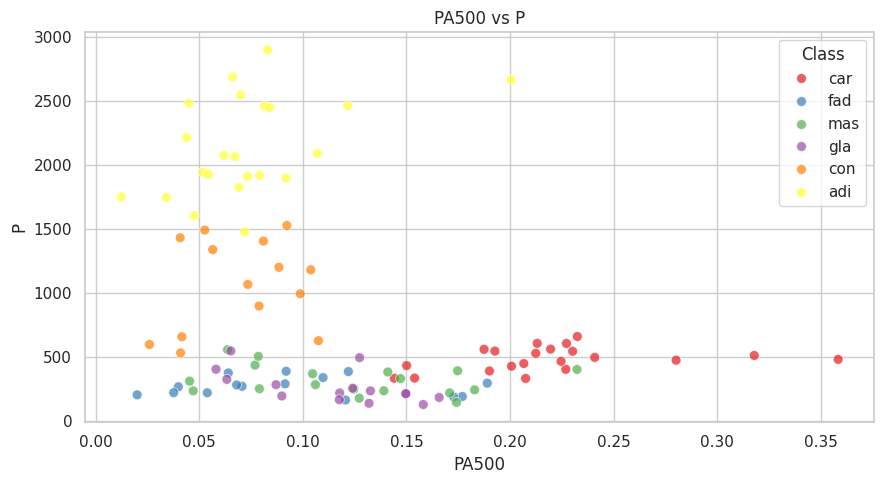

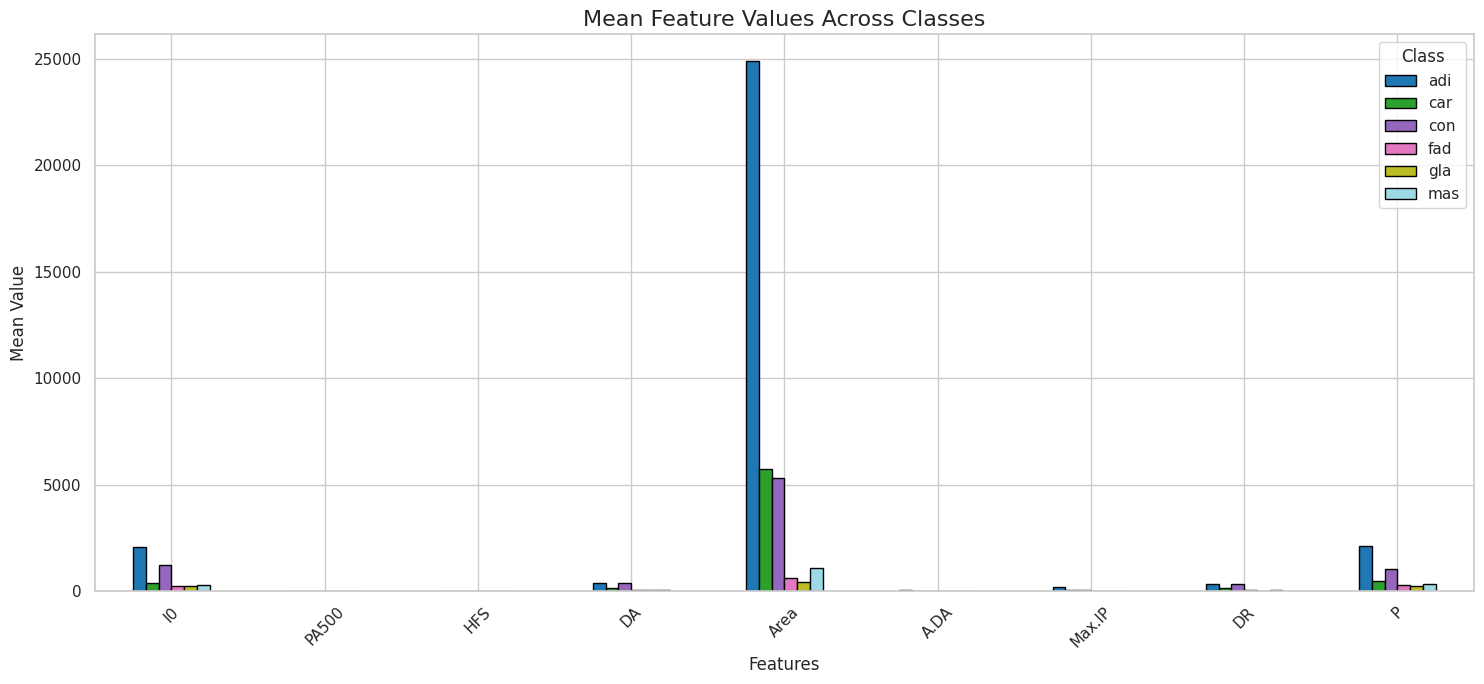

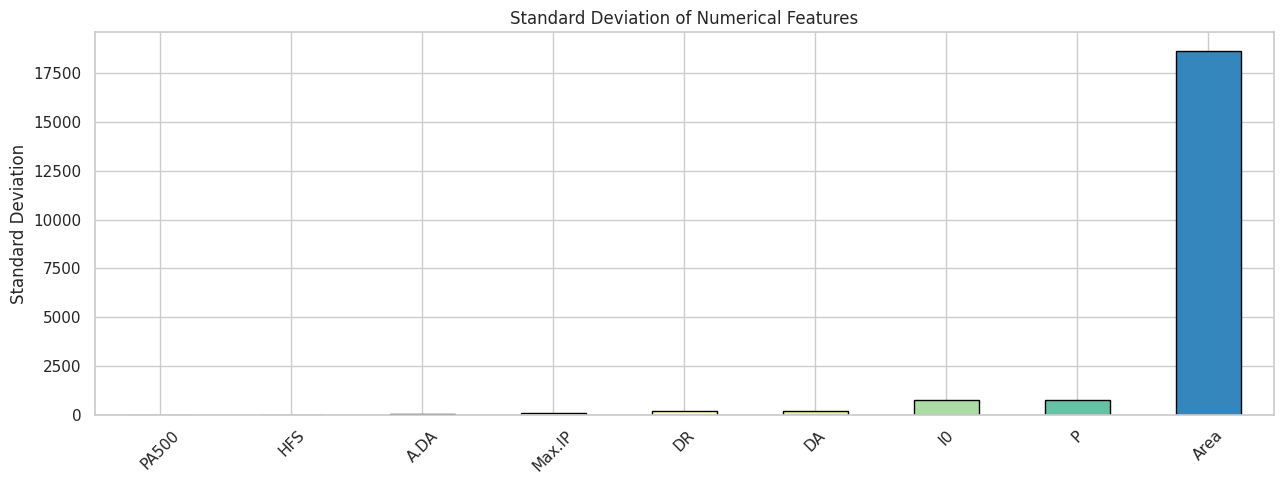

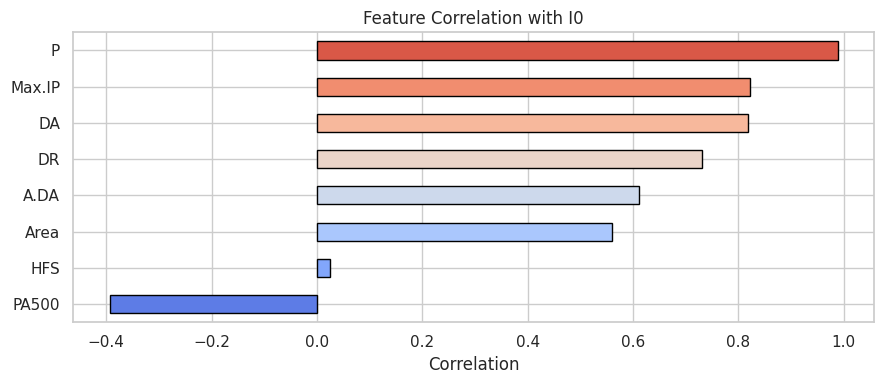

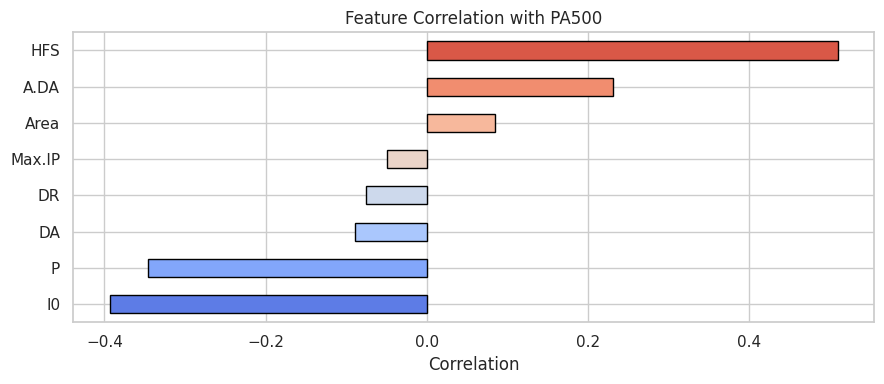

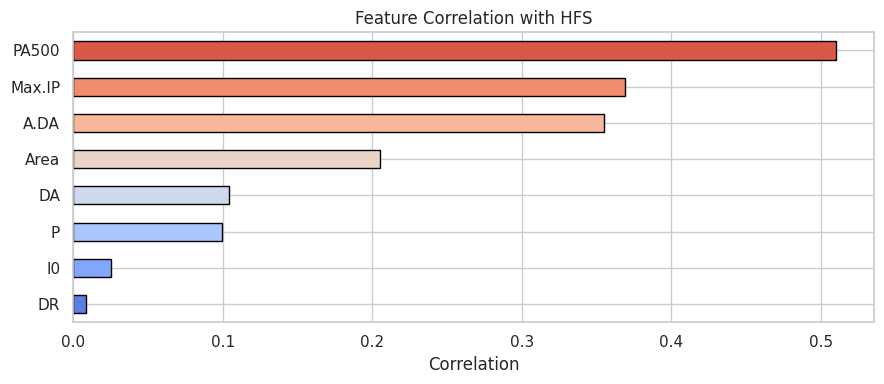

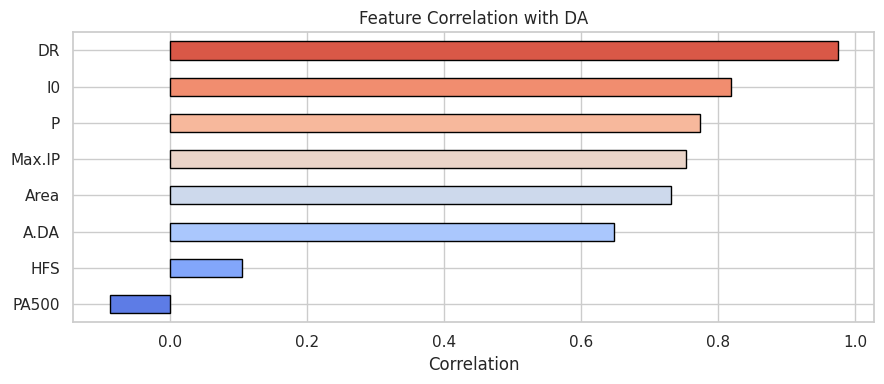

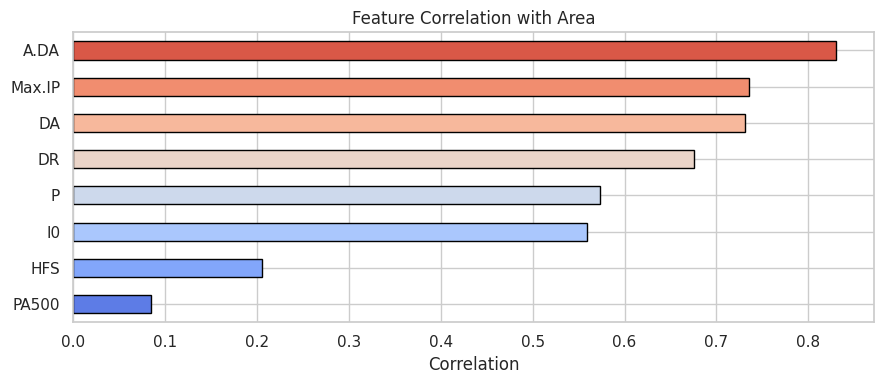

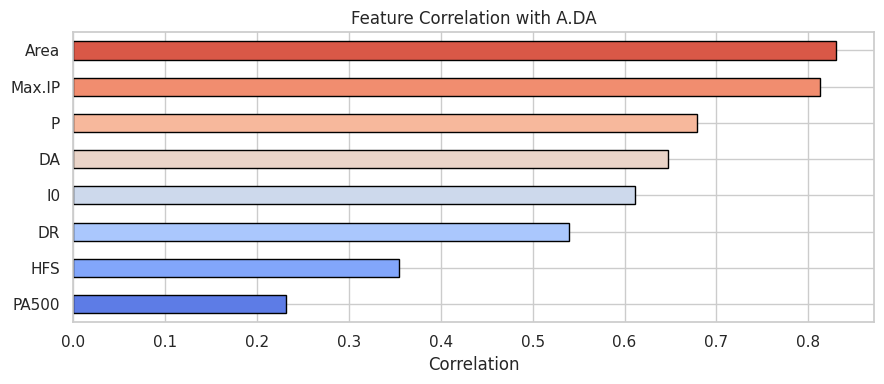

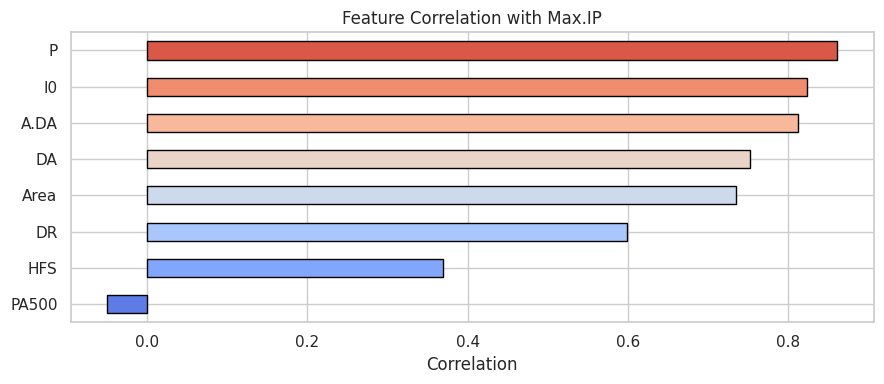

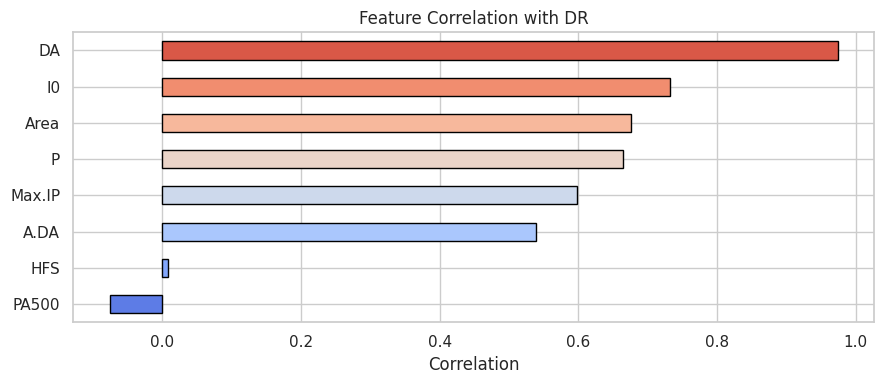

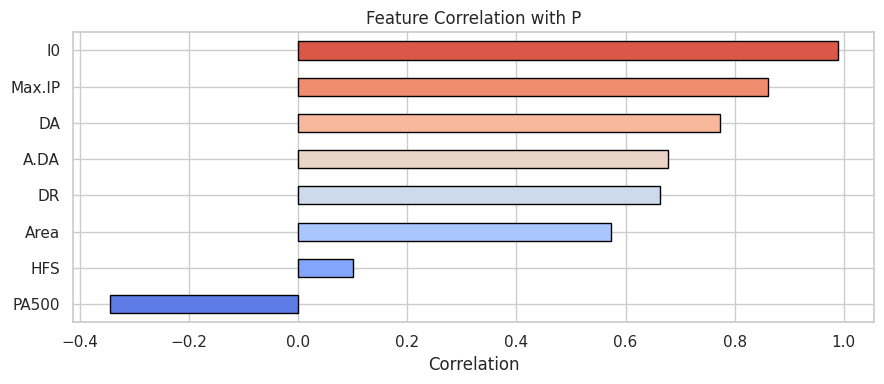


          EDA COMPLETED
Total Records: 105
Total Features: 10
Numerical Features: 9
Categorical Features: 1

Class Distribution:
Class
adi    22
car    21
mas    18
fad    15
gla    15
con    14
Name: count, dtype: int64

Numerical Feature Summary:
                I0       PA500         HFS           DA           Area  \
count   105.000000  105.000000  105.000000   105.000000     105.000000   
mean    789.844490    0.120013    0.115078   192.064908    7401.112381   
std     755.353498    0.068914    0.101754   191.090676   18656.955951   
min     103.000000    0.012392   -0.066323    19.647670      70.426239   
25%     250.000000    0.067195    0.043284    54.583080     409.647141   
50%     389.872978    0.104720    0.086568   120.901596    2475.557078   
75%    1496.736054    0.170868    0.166853   255.815179    7659.742134   
max    2800.000000    0.358316    0.467748  1063.441427  174480.476218   

             A.DA      Max.IP          DR            P  
count  105.000000  105.000

In [13]:

# ============================================================
# DETAILED DATA VISUALIZATION AND EDA
# ============================================================

# 1. IMPORT LIBRARIES
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.colors import LinearSegmentedColormap



# 3. DATASET INFORMATION
print("\n========== DATASET INFORMATION ==========")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nColumn Names:\n", df.columns)
print("\nData Types:\n", df.dtypes)
print("\nStatistical Summary:\n", df.describe(include='all'))
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

# 4. DATA CLEANING
df.columns = df.columns.str.strip()

df = df.drop_duplicates()

# Separate numerical and categorical columns
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("\nNumerical Columns:", numerical_cols)
print("\nCategorical Columns:", categorical_cols)

# 5. COLOR PALETTES
palettes = [
    'viridis', 'plasma', 'magma', 'coolwarm',
    'Spectral', 'Set2', 'husl', 'turbo'
]

sns.set_theme(style="whitegrid", font_scale=1.0)

# 6. DATASET OVERVIEW
plt.figure(figsize=(10, 5))
colors = sns.color_palette('Set2', 4)

overview = [
    df.shape[0],
    df.shape[1],
    df.isnull().sum().sum(),
    df.duplicated().sum()
]

labels = ['Rows', 'Columns', 'Missing Values', 'Duplicates']

bars = plt.bar(labels, overview, color=colors, edgecolor='black')

plt.title('Dataset Overview', fontsize=16, fontweight='bold')
plt.ylabel('Count')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        int(bar.get_height()),
        ha='center', va='bottom'
    )

plt.tight_layout()
plt.show()

# 7. MISSING VALUE VISUALIZATION
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cmap='magma',
    cbar=True,
    yticklabels=False
)

plt.title('Missing Values Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))

missing = df.isnull().sum()
missing = missing[missing > 0]

if len(missing) > 0:
    missing.sort_values().plot(
        kind='bar',
        color=sns.color_palette('rocket', len(missing)),
        edgecolor='black'
    )
    plt.title('Missing Values by Column')
    plt.ylabel('Missing Count')
    plt.xticks(rotation=45)
else:
    plt.text(0.5, 0.5, 'No Missing Values Found',
             ha='center', fontsize=16)
    plt.title('Missing Value Analysis')

plt.tight_layout()
plt.show()

# 8. CLASS DISTRIBUTION
if 'Class' in df.columns:

    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=df,
        x='Class',
        hue='Class',
        palette='Set2',
        legend=False,
        edgecolor='black'
    )

    plt.title('Class Distribution', fontsize=16, fontweight='bold')
    plt.xlabel('Class')
    plt.ylabel('Count')
    plt.xticks(rotation=30)

    plt.tight_layout()
    plt.show()

    # Pie chart
    plt.figure(figsize=(8, 8))

    df['Class'].value_counts().plot(
        kind='pie',
        autopct='%1.1f%%',
        startangle=90,
        cmap='Pastel1',
        wedgeprops={'edgecolor': 'black'}
    )

    plt.title('Class Percentage Distribution')
    plt.ylabel('')
    plt.show()


# 9. NUMERICAL FEATURE DISTRIBUTIONS - FIXED

# Generate enough colors for all numerical columns
colors = sns.color_palette('husl', n_colors=len(numerical_cols))

for i, col in enumerate(numerical_cols):

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Histogram
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        color=colors[i],
        edgecolor='black',
        ax=axes[0]
    )

    axes[0].set_title(
        f'{col} - Histogram Distribution',
        fontsize=13,
        fontweight='bold'
    )

    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Frequency')

    # KDE Plot
    sns.kdeplot(
        data=df,
        x=col,
        fill=True,
        color=colors[i],
        ax=axes[1]
    )

    axes[1].set_title(
        f'{col} - Density Distribution',
        fontsize=13,
        fontweight='bold'
    )

    axes[1].set_xlabel(col)
    axes[1].set_ylabel('Density')

    plt.tight_layout()
    plt.show()


# 10. BOXPLOT FOR OUTLIER DETECTION
for col in numerical_cols:

    plt.figure(figsize=(10, 4))

    sns.boxplot(
        data=df,
        x=col,
        color=sns.color_palette('pastel')[
            numerical_cols.index(col) % 8
        ],
        width=0.5
    )

    plt.title(f'Boxplot and Outlier Detection - {col}')
    plt.tight_layout()
    plt.show()

# 11. VIOLIN PLOTS BY CLASS
if 'Class' in df.columns:

    for col in numerical_cols:

        if col != 'Class':

            plt.figure(figsize=(10, 5))

            sns.violinplot(
                data=df,
                x='Class',
                y=col,
                hue='Class',
                palette='Set2',
                legend=False,
                inner='quartile'
            )

            plt.title(f'{col} Distribution Across Classes')
            plt.xticks(rotation=30)
            plt.tight_layout()
            plt.show()

# 12. FEATURE COMPARISON USING BAR PLOTS
for col in numerical_cols:

    if col != 'Class':

        plt.figure(figsize=(10, 5))

        if 'Class' in df.columns:
            sns.barplot(
                data=df,
                x='Class',
                y=col,
                hue='Class',
                palette='Spectral',
                errorbar=None,
                legend=False
            )

            plt.title(f'Average {col} by Class')

        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()

# 13. CORRELATION MATRIX
if len(numerical_cols) > 1:

    plt.figure(figsize=(13, 9))

    correlation = df[numerical_cols].corr()

    sns.heatmap(
        correlation,
        annot=True,
        cmap='coolwarm',
        fmt='.2f',
        linewidths=0.5,
        square=True,
        center=0
    )

    plt.title('Numerical Features Correlation Heatmap',
              fontsize=16, fontweight='bold')

    plt.tight_layout()
    plt.show()

# 14. PAIR PLOT
if len(numerical_cols) >= 2:

    pair_cols = numerical_cols[:]

    if len(pair_cols) > 6:
        pair_cols = pair_cols[:6]

    if 'Class' in df.columns:
        sns.pairplot(
            df[pair_cols + ['Class']].dropna(),
            hue='Class',
            palette='Set2',
            diag_kind='kde',
            corner=True
        )
    else:
        sns.pairplot(
            df[pair_cols].dropna(),
            diag_kind='kde',
            corner=True
        )

    plt.suptitle('Pairwise Feature Relationships', y=1.02)
    plt.show()

# 15. SCATTER PLOTS AGAINST CLASS
if 'Class' in df.columns:

    for col in numerical_cols:

        if col != 'Class':

            plt.figure(figsize=(10, 5))

            sns.stripplot(
                data=df,
                x='Class',
                y=col,
                hue='Class',
                palette='husl',
                jitter=0.25,
                alpha=0.65,
                legend=False
            )

            plt.title(f'{col} Values Across Classes')
            plt.xticks(rotation=30)
            plt.tight_layout()
            plt.show()

# 16. FEATURE RELATIONSHIP SCATTER PLOTS
if len(numerical_cols) >= 2:

    from itertools import combinations

    selected_features = numerical_cols[:]

    for x_col, y_col in list(
        combinations(selected_features, 2)
    )[:15]:

        plt.figure(figsize=(9, 5))

        if 'Class' in df.columns:

            sns.scatterplot(
                data=df,
                x=x_col,
                y=y_col,
                hue='Class',
                palette='Set1',
                alpha=0.7,
                s=50
            )

        else:

            sns.scatterplot(
                data=df,
                x=x_col,
                y=y_col,
                color='teal',
                alpha=0.7
            )

        plt.title(f'{x_col} vs {y_col}')
        plt.tight_layout()
        plt.show()

# 17. FEATURE-WISE MEAN COMPARISON
if 'Class' in df.columns:

    mean_data = df.groupby('Class')[numerical_cols].mean()

    mean_data.T.plot(
        kind='bar',
        figsize=(15, 7),
        colormap='tab20',
        edgecolor='black'
    )

    plt.title('Mean Feature Values Across Classes',
              fontsize=16)
    plt.xlabel('Features')
    plt.ylabel('Mean Value')
    plt.xticks(rotation=45)
    plt.legend(title='Class')
    plt.tight_layout()
    plt.show()

# 18. FEATURE-WISE STANDARD DEVIATION
plt.figure(figsize=(13, 5))

df[numerical_cols].std().sort_values().plot(
    kind='bar',
    color=sns.color_palette('Spectral', len(numerical_cols)),
    edgecolor='black'
)

plt.title('Standard Deviation of Numerical Features')
plt.ylabel('Standard Deviation')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 19. CORRELATION WITH EACH FEATURE
if len(numerical_cols) > 1:

    for col in numerical_cols:

        plt.figure(figsize=(9, 4))

        corr_values = (
            df[numerical_cols]
            .corr()[col]
            .drop(col)
            .sort_values()
        )

        corr_values.plot(
            kind='barh',
            color=sns.color_palette(
                'coolwarm', len(corr_values)
            ),
            edgecolor='black'
        )

        plt.title(f'Feature Correlation with {col}')
        plt.xlabel('Correlation')
        plt.tight_layout()
        plt.show()

# 20. FINAL SUMMARY
print("\n========================================")
print("          EDA COMPLETED")
print("========================================")

print("Total Records:", len(df))
print("Total Features:", len(df.columns))
print("Numerical Features:", len(numerical_cols))
print("Categorical Features:", len(categorical_cols))

print("\nClass Distribution:")

if 'Class' in df.columns:
    print(df['Class'].value_counts())

print("\nNumerical Feature Summary:")
print(df[numerical_cols].describe())

print("\nVisualization and EDA Completed Successfully!")


## Feature engineering

========== DATASET INFORMATION ==========
  Class          I0     PA500       HFS          DA          Area       A.DA  \
0   car  524.794072  0.187448  0.032114  228.800228   6843.598481  29.910803   
1   car  330.000000  0.226893  0.265290  121.154201   3163.239472  26.109202   
2   car  551.879287  0.232478  0.063530  264.804935  11888.391827  44.894903   
3   car  380.000000  0.240855  0.286234  137.640111   5402.171180  39.248524   
4   car  362.831266  0.200713  0.244346  124.912559   3290.462446  26.342127   

      Max.IP          DR           P  
0  60.204880  220.737212  556.828334  
1  69.717361   99.084964  400.225776  
2  77.793297  253.785300  656.769449  
3  88.758446  105.198568  493.701814  
4  69.389389  103.866552  424.796503  

Shape: (105, 10)

Columns: ['Class', 'I0', 'PA500', 'HFS', 'DA', 'Area', 'A.DA', 'Max.IP', 'DR', 'P']

Data Types:
 Class      object
I0        float64
PA500     float64
HFS       float64
DA        float64
Area      float64
A.DA      float64


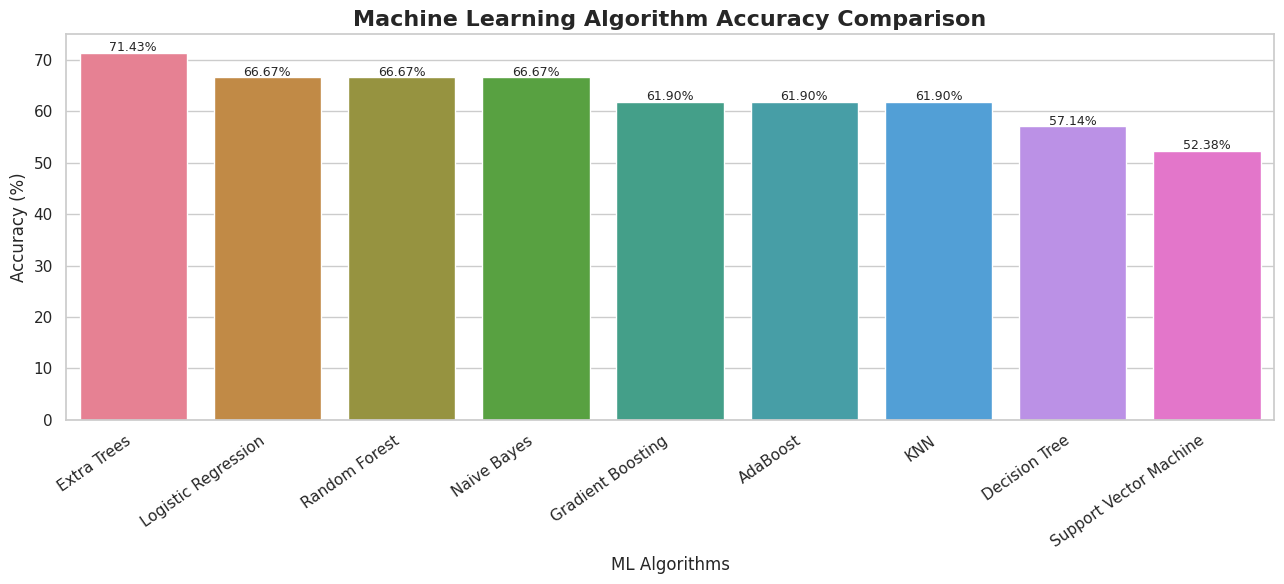

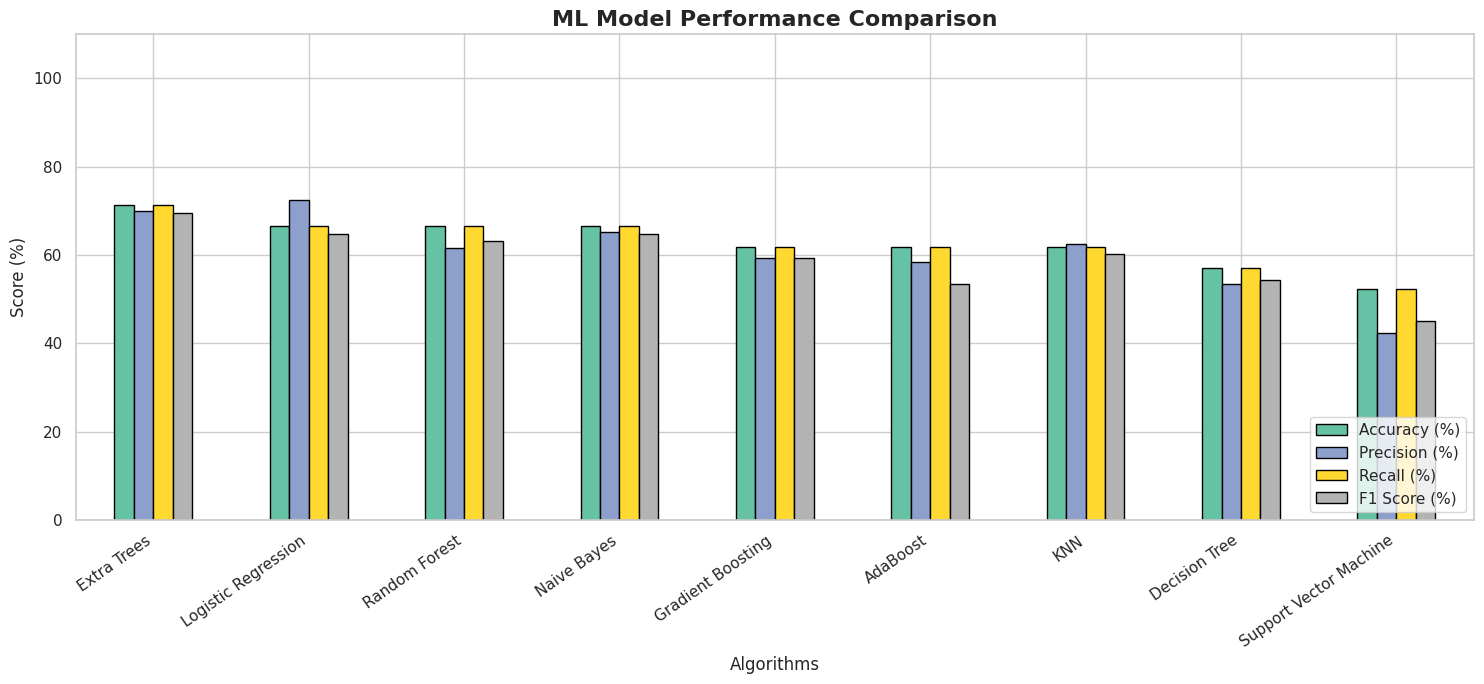

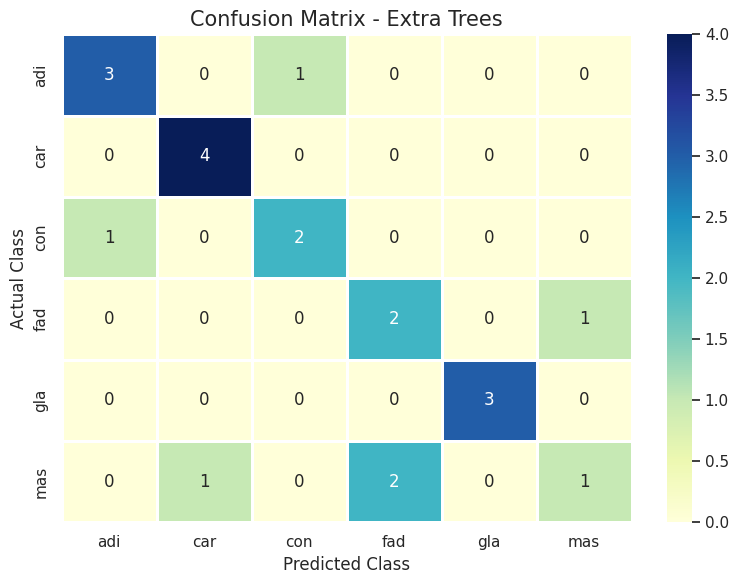

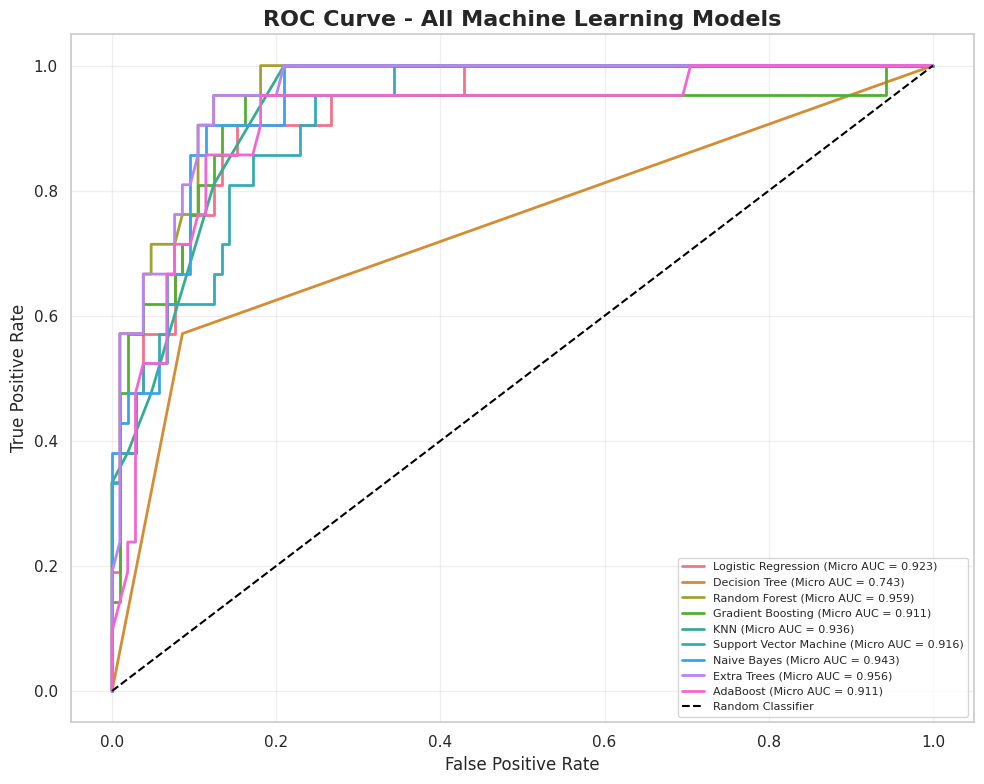

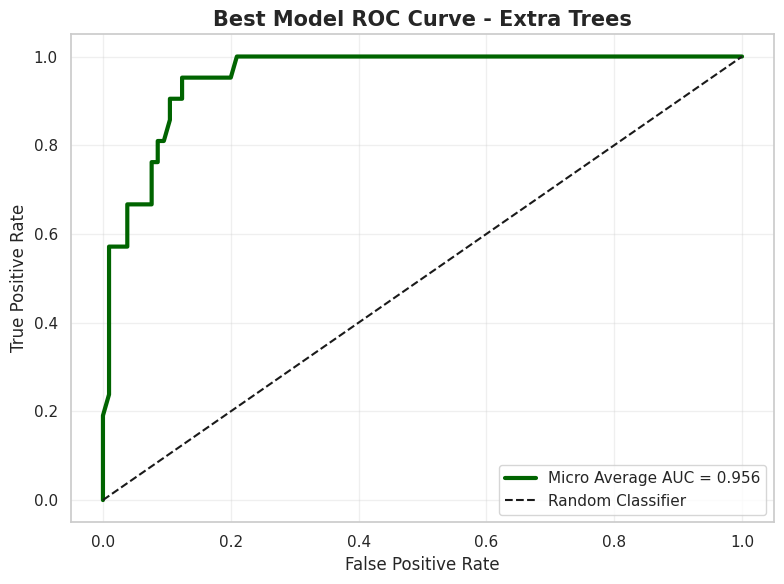


MACHINE LEARNING CLASSIFICATION COMPLETED

Best Algorithm: Extra Trees
Best Accuracy: 71.43%

Final Results:
                Algorithm  Accuracy (%)  Precision (%)  Recall (%)  \
0             Extra Trees         71.43          70.00       71.43   
1     Logistic Regression         66.67          72.38       66.67   
2           Random Forest         66.67          61.67       66.67   
3             Naive Bayes         66.67          65.24       66.67   
4       Gradient Boosting         61.90          59.29       61.90   
5                AdaBoost         61.90          58.50       61.90   
6                     KNN         61.90          62.47       61.90   
7           Decision Tree         57.14          53.33       57.14   
8  Support Vector Machine         52.38          42.38       52.38   

   F1 Score (%)  ROC AUC (%)  
0         69.54        94.17  
1         64.69        90.95  
2         63.19        94.16  
3         64.78        93.29  
4         59.38        89.38  
5  

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score
)

print("========== DATASET INFORMATION ==========")
print(df.head())
print("\nShape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData Types:\n", df.dtypes)
print("\nMissing Values:\n", df.isnull().sum())

# 3. DATA CLEANING

df.columns = df.columns.str.strip()

df = df.drop_duplicates().copy()

# Remove rows with missing target values
df = df.dropna(subset=['Class']).copy()

# Target column
target = 'Class'

# Features and target
X = df.drop(columns=[target]).copy()
y = df[target].copy()

print("\nTarget Distribution:")
print(y.value_counts())

# 4. TRAIN TEST SPLITTING
# Split BEFORE fitting encoders and scalers

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\n========== TRAIN TEST SPLIT ==========")
print("X Train:", X_train.shape)
print("X Test:", X_test.shape)
print("Y Train:", y_train.shape)
print("Y Test:", y_test.shape)

# 5. LABEL ENCODING TARGET

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.transform(y_test)

class_names = label_encoder.classes_
n_classes = len(class_names)

print("\nEncoded Classes:")
for i, name in enumerate(class_names):
    print(name, "=", i)

# 6. ENCODE CATEGORICAL FEATURES

categorical_cols = X_train.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

# Convert numerical columns to numeric
for col in numerical_cols:
    X_train[col] = pd.to_numeric(X_train[col], errors='coerce')
    X_test[col] = pd.to_numeric(X_test[col], errors='coerce')

# Impute numerical missing values
num_imputer = SimpleImputer(strategy='median')

if len(numerical_cols) > 0:
    X_train[numerical_cols] = num_imputer.fit_transform(
        X_train[numerical_cols]
    )

    X_test[numerical_cols] = num_imputer.transform(
        X_test[numerical_cols]
    )

# Label encode categorical columns
for col in categorical_cols:

    X_train[col] = X_train[col].fillna('Missing').astype(str)
    X_test[col] = X_test[col].fillna('Missing').astype(str)

    le = LabelEncoder()

    X_train[col] = le.fit_transform(X_train[col])

    # Handle categories that were not present in training
    mapping = {
        value: index
        for index, value in enumerate(le.classes_)
    }

    X_test[col] = (
        X_test[col]
        .map(mapping)
        .fillna(-1)
        .astype(int)
    )

# 7. FEATURE SCALING

scaler = StandardScaler()

X_train = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("\n========== PREPROCESSING COMPLETED ==========")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# 8. DEFINE MACHINE LEARNING ALGORITHMS

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Support Vector Machine': SVC(
        probability=True,
        random_state=42
    ),

    'Naive Bayes': GaussianNB(),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=200,
        random_state=42
    ),

    'AdaBoost': AdaBoostClassifier(
        random_state=42
    )
}

# 9. TRAIN MODELS AND EVALUATE PERFORMANCE

results = []
trained_models = {}
model_probabilities = {}

for name, model in models.items():

    print("\n" + "="*60)
    print("Training:", name)
    print("="*60)

    try:

        # Train model
        model.fit(X_train, y_train)

        # Predictions
        y_pred = model.predict(X_test)

        # Predicted probabilities
        y_prob = model.predict_proba(X_test)

        # Accuracy
        accuracy = accuracy_score(y_test, y_pred) * 100

        # Precision
        precision = precision_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ) * 100

        # Recall
        recall = recall_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ) * 100

        # F1 Score
        f1 = f1_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ) * 100

        # ROC AUC
        if n_classes == 2:
            roc_auc = roc_auc_score(y_test, y_prob[:, 1])
        else:
            y_test_binary = label_binarize(
                y_test,
                classes=np.arange(n_classes)
            )

            roc_auc = roc_auc_score(
                y_test_binary,
                y_prob,
                average='macro',
                multi_class='ovr'
            )

        results.append({
            'Algorithm': name,
            'Accuracy (%)': accuracy,
            'Precision (%)': precision,
            'Recall (%)': recall,
            'F1 Score (%)': f1,
            'ROC AUC (%)': roc_auc * 100
        })

        trained_models[name] = model
        model_probabilities[name] = y_prob

        print(f"Accuracy  : {accuracy:.2f}%")
        print(f"Precision : {precision:.2f}%")
        print(f"Recall    : {recall:.2f}%")
        print(f"F1 Score  : {f1:.2f}%")
        print(f"ROC AUC   : {roc_auc * 100:.2f}%")

        print("\nClassification Report:\n")

        print(classification_report(
            y_test,
            y_pred,
            labels=np.arange(n_classes),
            target_names=[str(c) for c in class_names],
            zero_division=0
        ))

    except Exception as e:
        print("Model failed:", name)
        print("Error:", str(e))

# 10. MODEL COMPARISON TABLE

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='Accuracy (%)',
    ascending=False
).reset_index(drop=True)

print("\n========== FINAL MODEL COMPARISON ==========")
print(results_df.round(2).to_string(index=False))

# 11. BEST MODEL

if len(results_df) > 0:

    best_model_name = results_df.iloc[0]['Algorithm']
    best_accuracy = results_df.iloc[0]['Accuracy (%)']

    print("\n====================================")
    print("BEST MACHINE LEARNING MODEL")
    print("====================================")
    print("Algorithm:", best_model_name)
    print(f"Accuracy: {best_accuracy:.2f}%")

    best_model = trained_models[best_model_name]

    best_predictions = best_model.predict(X_test)

# 12. ACCURACY COMPARISON GRAPH

if len(results_df) > 0:

    plt.figure(figsize=(13, 6))

    sns.barplot(
        data=results_df,
        x='Algorithm',
        y='Accuracy (%)',
        hue='Algorithm',
        palette='husl',
        legend=False
    )

    plt.title(
        'Machine Learning Algorithm Accuracy Comparison',
        fontsize=16,
        fontweight='bold'
    )

    plt.ylabel('Accuracy (%)')
    plt.xlabel('ML Algorithms')
    plt.xticks(rotation=35, ha='right')

    for i, value in enumerate(results_df['Accuracy (%)']):
        plt.text(i, value + 0.3, f'{value:.2f}%',
                 ha='center', fontsize=9)

    plt.tight_layout()
    plt.show()

# 13. PERFORMANCE COMPARISON GRAPH

if len(results_df) > 0:

    metrics = [
        'Accuracy (%)',
        'Precision (%)',
        'Recall (%)',
        'F1 Score (%)'
    ]

    results_df.set_index('Algorithm')[metrics].plot(
        kind='bar',
        figsize=(15, 7),
        colormap='Set2',
        edgecolor='black'
    )

    plt.title(
        'ML Model Performance Comparison',
        fontsize=16,
        fontweight='bold'
    )

    plt.ylabel('Score (%)')
    plt.xlabel('Algorithms')
    plt.xticks(rotation=35, ha='right')
    plt.ylim(0, 110)
    plt.legend(loc='lower right')

    plt.tight_layout()
    plt.show()

# 14. CONFUSION MATRIX FOR BEST MODEL

if len(results_df) > 0:

    cm = confusion_matrix(
        y_test,
        best_predictions,
        labels=np.arange(n_classes)
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='YlGnBu',
        linewidths=1,
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(
        f'Confusion Matrix - {best_model_name}',
        fontsize=15
    )

    plt.xlabel('Predicted Class')
    plt.ylabel('Actual Class')

    plt.tight_layout()
    plt.show()

# 15. ROC CURVE FOR ALL MODELS

plt.figure(figsize=(10, 8))

colors = sns.color_palette(
    'husl',
    n_colors=max(len(trained_models), 1)
)

for i, (name, y_prob) in enumerate(
    model_probabilities.items()
):

    if n_classes == 2:

        fpr, tpr, thresholds = roc_curve(
            y_test,
            y_prob[:, 1]
        )

        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            color=colors[i],
            linewidth=2,
            label=f'{name} (AUC = {roc_auc:.3f})'
        )

    else:

        # Multiclass ROC: micro-average
        y_test_binary = label_binarize(
            y_test,
            classes=np.arange(n_classes)
        )

        fpr, tpr, thresholds = roc_curve(
            y_test_binary.ravel(),
            y_prob.ravel()
        )

        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            color=colors[i],
            linewidth=2,
            label=f'{name} (Micro AUC = {roc_auc:.3f})'
        )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    label='Random Classifier'
)

plt.title(
    'ROC Curve - All Machine Learning Models',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend(
    loc='lower right',
    fontsize=8
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 16. INDIVIDUAL ROC CURVE FOR BEST MODEL

if len(results_df) > 0:

    best_prob = model_probabilities[best_model_name]

    plt.figure(figsize=(8, 6))

    if n_classes == 2:

        fpr, tpr, thresholds = roc_curve(
            y_test,
            best_prob[:, 1]
        )

        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            color='darkorange',
            linewidth=3,
            label=f'AUC = {roc_auc:.3f}'
        )

    else:

        y_test_binary = label_binarize(
            y_test,
            classes=np.arange(n_classes)
        )

        fpr, tpr, thresholds = roc_curve(
            y_test_binary.ravel(),
            best_prob.ravel()
        )

        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            color='darkgreen',
            linewidth=3,
            label=f'Micro Average AUC = {roc_auc:.3f}'
        )

    plt.plot(
        [0, 1], [0, 1],
        'k--',
        label='Random Classifier'
    )

    plt.title(
        f'Best Model ROC Curve - {best_model_name}',
        fontsize=15,
        fontweight='bold'
    )

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

# 17. FINAL OUTPUT

print("\n" + "="*60)
print("MACHINE LEARNING CLASSIFICATION COMPLETED")
print("="*60)

if len(results_df) > 0:

    print("\nBest Algorithm:", best_model_name)
    print(f"Best Accuracy: {best_accuracy:.2f}%")

    print("\nFinal Results:")
    print(results_df.round(2))

    print("\nAll models trained successfully where supported.")
    print("ROC curves generated successfully.")

else:
    print("No model completed successfully. Check the dataset.")


## Thank you..pls upvote!!!!!!!!!!!